Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/Unified3Group_ER_Evolution_25TF

COHORT SPLIT
Rows: 241

ALL ER EVOLUTION STATES
ER retained    179
Stable ER-      40
ER loss         20
ER gain          2
Name: Evolution_state, dtype: int64

TARGET 3-GROUP COHORT
ER retained    179
Stable ER-      40
ER loss         20
Name: Evolution_state, dtype: int64

Total: 239

CLOSEST-DRAW AUDIT
Patients: 244
Positive    183
Negative     61
Name: met_ER, dtype: int64

MATCH TO CLOSEST-DRAW AUDIT
both          239
left_only       0
right_only      0
Name: _merge, dtype: int64

METASTATIC ER CONCORDANCE
met_ER           Negative  Positive
Evolution_state                    
ER loss                20         0
ER retained             0       179
Stable ER-             40         0

Discordant patients: 0

3-GROUP QC
ER retained    179
Stable ER-      40
ER loss         20
Name: Evolution_state, dtype: int64

Total: 23

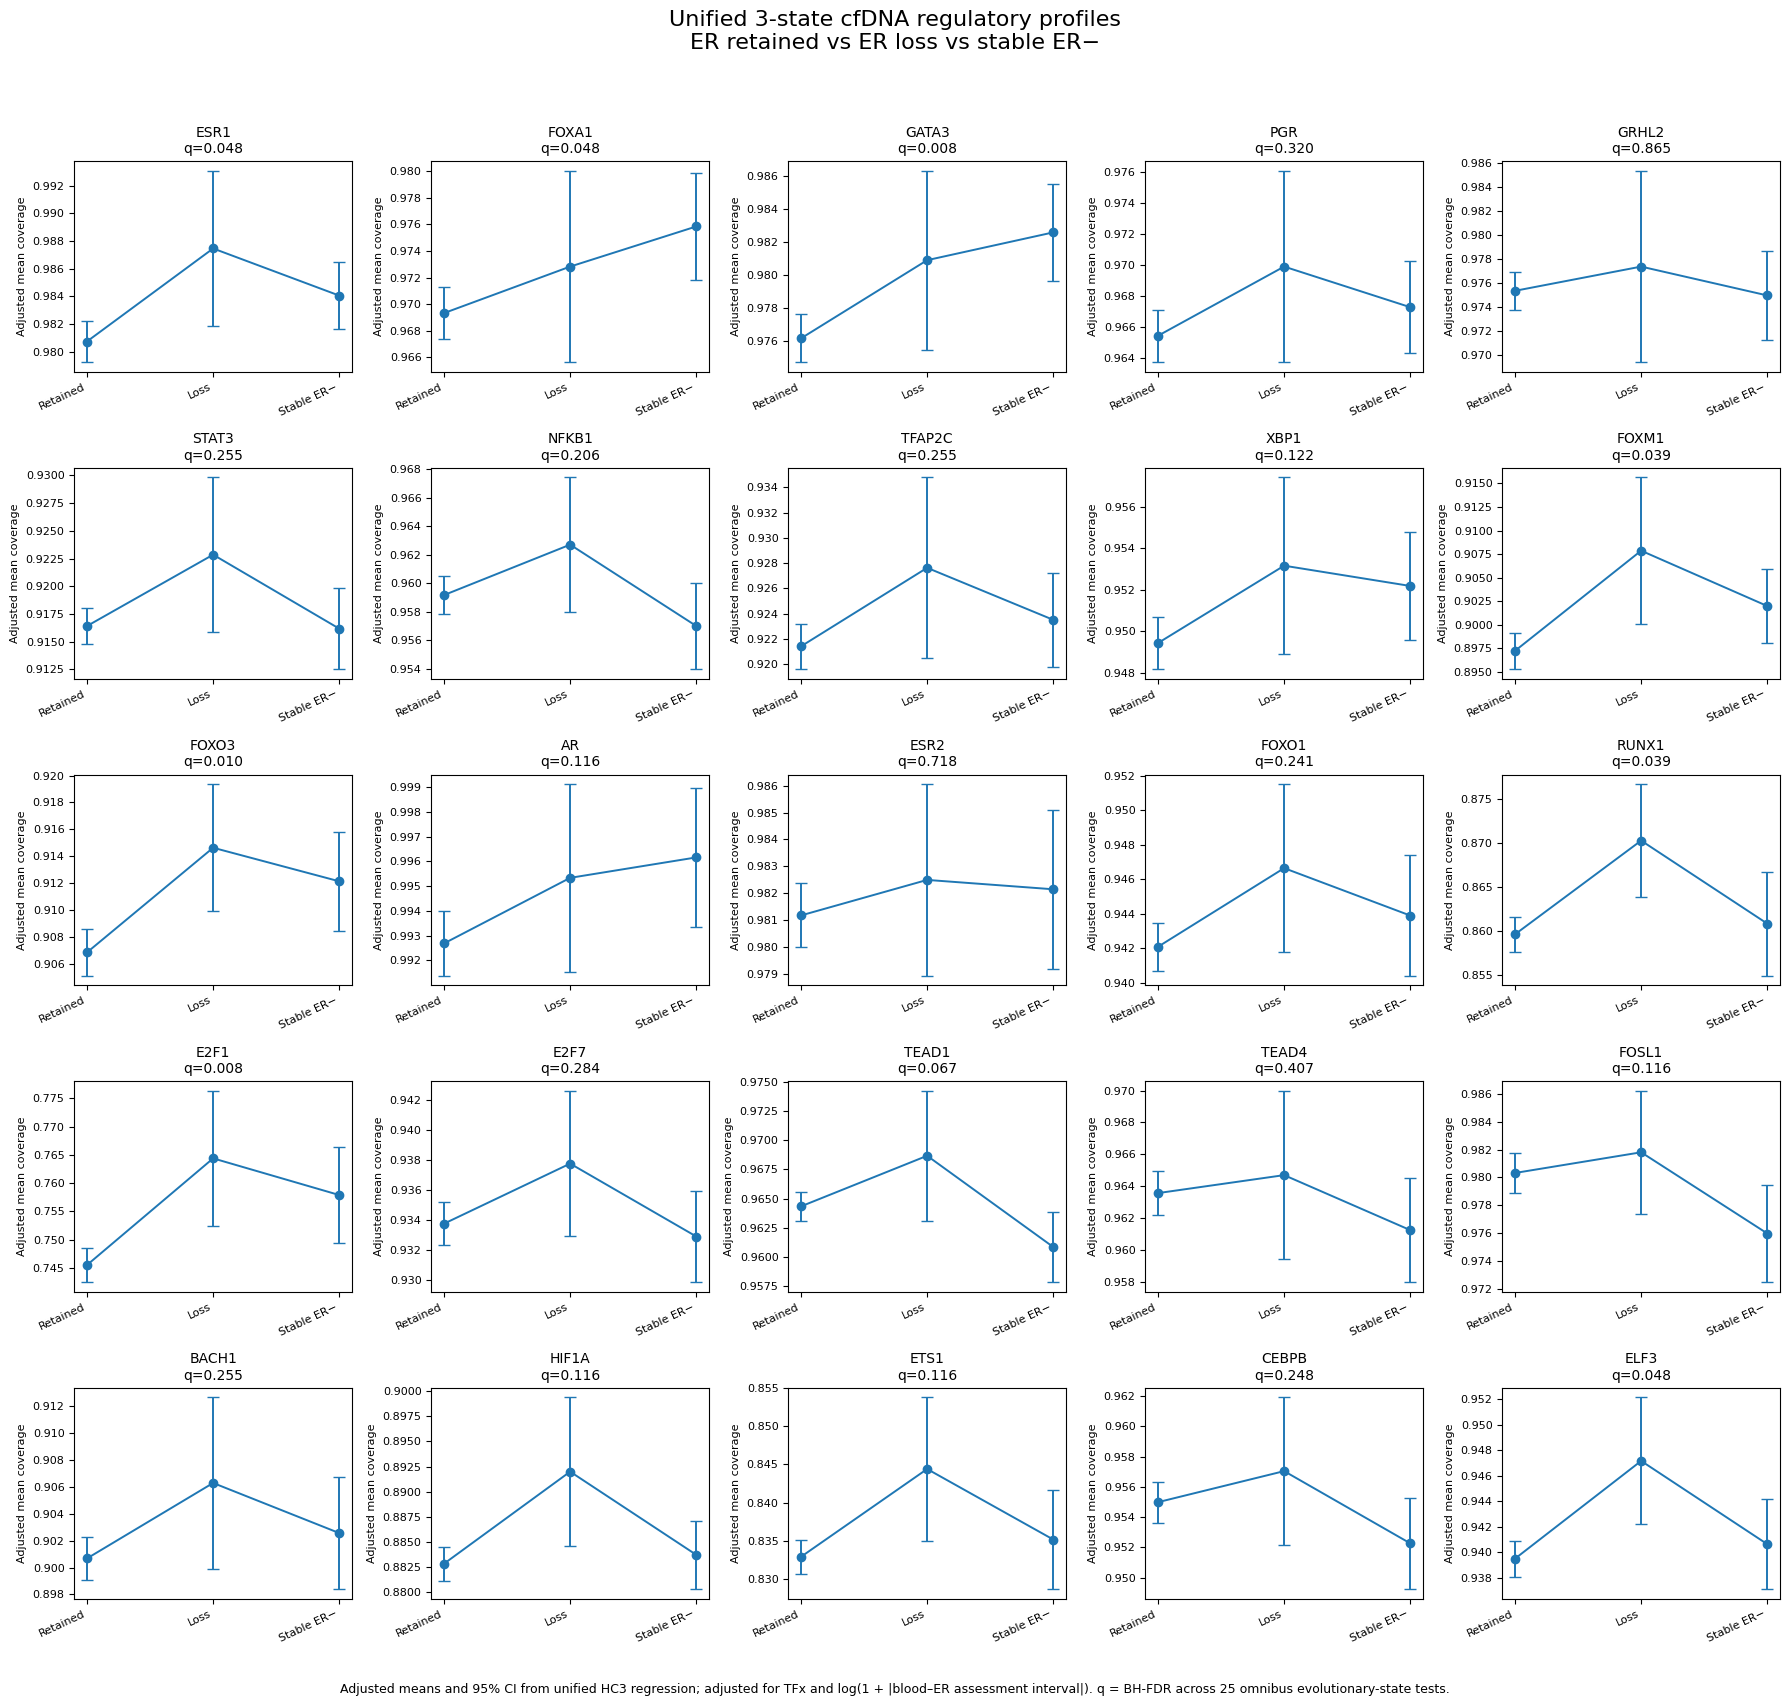



FINAL UNIFIED ANALYSIS SUMMARY

Model:
TFBS mean coverage ~ Evolution_state + TFx_pct + log(1 + abs_lag_days)

Reference state:
ER retained

Primary test:
2-df omnibus evolutionary-state Wald test

Omnibus FDR-significant TFBS:
8/25

Planned contrasts:
1. ER loss - ER retained
2. Stable ER- - ER retained
3. ER loss - Stable ER-

Outputs:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/Unified3Group_ER_Evolution_25TF


In [1]:
#!/usr/bin/env python3

# ======================================================================
# Q2) UNIFIED 3-GROUP ER EVOLUTIONARY-STATE ANALYSIS
#
# Groups:
#
#   ER retained:
#       Primary ER+ -> Metastatic ER+
#       expected n = 179
#
#   ER loss:
#       Primary ER+ -> Metastatic ER-
#       expected n = 20
#
#   Stable ER-:
#       Primary ER- -> Metastatic ER-
#       expected n = 40
#
# Total expected:
#       n = 239
#
# Griffin sample:
#   Closest available Griffin blood draw to the first informative
#   metastatic ER assessment.
#
# PRIMARY METRIC:
#   Mean coverage
#
# Unified model for each TFBS:
#
#   Mean coverage ~ Evolution_state
#                   + TFx_pct
#                   + log(1 + abs_lag_days)
#
# ER retained is the reference state.
#
# PRIMARY INFERENCE:
#   2-df omnibus Wald test:
#
#       H0:
#       ER loss = ER retained
#       AND
#       Stable ER- = ER retained
#
#   BH-FDR across 25 omnibus tests.
#
# PLANNED CONTRASTS:
#
#   1. ER loss - ER retained
#   2. Stable ER- - ER retained
#   3. ER loss - Stable ER-
#
#   BH-FDR separately across 25 TFBS for each contrast.
#
# Sensitivity:
#   BH-FDR across all 75 pairwise contrast tests.
#
# Statistics:
#   OLS with HC3 heteroskedasticity-robust covariance.
#
# Adjusted group means:
#   Model-predicted mean coverage at cohort-average TFx and log-lag.
#
# Seed = 1234
# ======================================================================


# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import norm, chi2

from statsmodels.stats.multitest import multipletests


SEED = 1234

rng = np.random.default_rng(SEED)


# ======================================================================
# 1. PATHS
# ======================================================================

AURORA_BASE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA"
)


# Patient-level ER evolution endpoint
SPLIT_TSV = (
    AURORA_BASE
    / "Griffin"
    / "Downstream"
    / "AURORA_Griffin_Heldout_Test_ER"
    / "Cohort_split.tsv"
)


# Closest Griffin draw to metastatic ER assessment
BASE_DIR = (
    AURORA_BASE
    / "Griffin"
    / "Downstream"
    / "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)


CLOSEST_AUDIT = (
    BASE_DIR
    / "ClosestDraw_MetER_patient_audit.tsv"
)


# Updated 44-TF Griffin workbook
GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)


OUT_DIR = (
    BASE_DIR
    / "Unified3Group_ER_Evolution_25TF"
)


OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("Output directory:")
print(OUT_DIR)


# ======================================================================
# 2. FIXED 25-TF PANEL
# ======================================================================

TF25 = [

    "ESR1",
    "FOXA1",
    "GATA3",
    "PGR",
    "GRHL2",
    "STAT3",
    "NFKB1",
    "TFAP2C",
    "XBP1",
    "FOXM1",
    "FOXO3",

    "AR",
    "ESR2",
    "FOXO1",
    "RUNX1",
    "E2F1",
    "E2F7",
    "TEAD1",
    "TEAD4",
    "FOSL1",
    "BACH1",
    "HIF1A",
    "ETS1",
    "CEBPB",
    "ELF3"
]


assert len(TF25) == 25


MEAN_FEATURES = [

    f"{tf}_mean_coverage"

    for tf in TF25
]


# ======================================================================
# 3. HELPER FUNCTIONS
# ======================================================================

def normalize_patient_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    try:

        f = float(x)

        if f.is_integer():
            return str(int(f))

    except (TypeError, ValueError):
        pass

    return x


def normalize_sample_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.startswith("AUP-"):
        x = x[4:]

    return x


def normalize_er(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if x in {
        "positive",
        "pos",
        "+",
        "er+"
    }:
        return "Positive"

    if x in {
        "negative",
        "neg",
        "-",
        "er-"
    }:
        return "Negative"

    return np.nan


# ======================================================================
# 4. LOAD COHORT SPLIT
# ======================================================================

split = pd.read_csv(
    SPLIT_TSV,
    sep="\t",
    dtype={"patient_id": str}
)


print("\n==============================================")
print("COHORT SPLIT")
print("==============================================")


print(
    "Rows:",
    len(split)
)


split["patient_id_norm"] = (
    split["patient_id"]
    .map(normalize_patient_id)
)


split["Primary_tumor_ER"] = (
    split["Primary_tumor_ER"]
    .map(normalize_er)
)


# ======================================================================
# 5. DEFINE METASTATIC ER ENDPOINT
# ======================================================================

if "Earliest_metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Earliest_metastatic_ER"]
        .map(normalize_er)
    )


elif "Metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Metastatic_ER"]
        .map(normalize_er)
    )


else:

    raise ValueError(
        "Could not find Earliest_metastatic_ER or Metastatic_ER."
    )


# ======================================================================
# 6. DEFINE ALL ER EVOLUTIONARY STATES
# ======================================================================

split["Evolution_state"] = np.select(

    [

        (
            split["Primary_tumor_ER"].eq("Positive")
            &
            split["Metastatic_ER"].eq("Positive")
        ),

        (
            split["Primary_tumor_ER"].eq("Positive")
            &
            split["Metastatic_ER"].eq("Negative")
        ),

        (
            split["Primary_tumor_ER"].eq("Negative")
            &
            split["Metastatic_ER"].eq("Negative")
        ),

        (
            split["Primary_tumor_ER"].eq("Negative")
            &
            split["Metastatic_ER"].eq("Positive")
        )

    ],

    [

        "ER retained",
        "ER loss",
        "Stable ER-",
        "ER gain"

    ],

    default="Other/Unknown"
)


print("\n==============================================")
print("ALL ER EVOLUTION STATES")
print("==============================================")


print(
    split["Evolution_state"]
    .value_counts()
)


# ======================================================================
# 7. KEEP ONLY THE THREE INFERENTIAL GROUPS
#
# ER gain n=2 is NOT included in formal inference.
# ======================================================================

evolution = split.loc[

    split["Evolution_state"].isin(
        [
            "ER retained",
            "ER loss",
            "Stable ER-"
        ]
    )

].copy()


# ----------------------------------------------------------------------
# Check for duplicate patient IDs.
# We should not silently drop conflicting endpoint assignments.
# ----------------------------------------------------------------------

dup = evolution.loc[
    evolution["patient_id_norm"].duplicated(
        keep=False
    )
].copy()


if len(dup) > 0:

    consistency = (

        dup
        .groupby("patient_id_norm")
        ["Evolution_state"]
        .nunique()
    )


    conflicting = consistency.loc[
        consistency > 1
    ]


    if len(conflicting) > 0:

        raise ValueError(

            "Conflicting ER evolution labels detected for patients:\n"
            +
            "\n".join(
                conflicting.index.astype(str)
            )
        )


# We need only patient-level labels.
# DO NOT use the sample column from Cohort_split.

evolution = (

    evolution[
        [
            "patient_id_norm",
            "Primary_tumor_ER",
            "Metastatic_ER",
            "Evolution_state"
        ]
    ]

    .drop_duplicates(
        subset="patient_id_norm"
    )
)


print("\n==============================================")
print("TARGET 3-GROUP COHORT")
print("==============================================")


print(
    evolution["Evolution_state"]
    .value_counts()
)


print(
    "\nTotal:",
    len(evolution)
)


# Expected:
#
# ER retained    179
# ER loss         20
# Stable ER-      40
#
# Total          239


# ======================================================================
# 8. LOAD CLOSEST-DRAW AUDIT
# ======================================================================

closest = pd.read_csv(
    CLOSEST_AUDIT,
    sep="\t",
    dtype={"patient_id": str}
)


closest["patient_id_norm"] = (
    closest["patient_id"]
    .map(normalize_patient_id)
)


closest["selected_sample"] = (
    closest["selected_sample"]
    .map(normalize_sample_id)
)


closest["TFx_pct"] = pd.to_numeric(
    closest["TFx_pct"],
    errors="coerce"
)


closest["abs_lag_days"] = pd.to_numeric(
    closest["abs_lag_days"],
    errors="coerce"
)


# Timing covariate
closest["log_abs_lag"] = np.log1p(
    closest["abs_lag_days"]
)


print("\n==============================================")
print("CLOSEST-DRAW AUDIT")
print("==============================================")


print(
    "Patients:",
    len(closest)
)


print(
    closest["met_ER"]
    .value_counts()
)


# ======================================================================
# 9. MERGE EVOLUTION LABEL WITH CLOSEST-DRAW DATA
# ======================================================================

analysis = evolution.merge(

    closest,

    on="patient_id_norm",

    how="left",

    validate="one_to_one",

    indicator=True
)


print("\n==============================================")
print("MATCH TO CLOSEST-DRAW AUDIT")
print("==============================================")


print(
    analysis["_merge"]
    .value_counts()
)


unmatched = analysis.loc[
    analysis["_merge"] != "both"
]


if len(unmatched) > 0:

    print(
        "\nPatients not found in closest-draw audit:"
    )

    print(

        unmatched[
            [
                "patient_id_norm",
                "Evolution_state"
            ]
        ]
        .to_string(
            index=False
        )
    )


analysis = analysis.loc[
    analysis["_merge"] == "both"
].copy()


analysis = analysis.drop(
    columns="_merge"
)


# ======================================================================
# 10. CRITICAL METASTATIC ER CONCORDANCE QC
# ======================================================================

analysis["Expected_met_ER"] = np.select(

    [

        analysis["Evolution_state"].eq(
            "ER retained"
        ),

        analysis["Evolution_state"].eq(
            "ER loss"
        ),

        analysis["Evolution_state"].eq(
            "Stable ER-"
        )

    ],

    [

        "Positive",
        "Negative",
        "Negative"

    ],

    default=np.nan
)


analysis["MetER_concordant"] = (

    analysis["met_ER"]
    ==
    analysis["Expected_met_ER"]
)


print("\n==============================================")
print("METASTATIC ER CONCORDANCE")
print("==============================================")


print(

    pd.crosstab(

        analysis["Evolution_state"],

        analysis["met_ER"]
    )
)


discordant = analysis.loc[
    ~analysis["MetER_concordant"]
]


print(
    "\nDiscordant patients:",
    len(discordant)
)


if len(discordant) > 0:

    print(

        discordant[
            [
                "patient_id_norm",
                "Evolution_state",
                "Metastatic_ER",
                "met_ER"
            ]
        ]
        .to_string(
            index=False
        )
    )


    raise ValueError(
        "Metastatic ER endpoint mismatch."
    )


# ======================================================================
# 11. COHORT QC
# ======================================================================

group_counts = (
    analysis["Evolution_state"]
    .value_counts()
)


print("\n==============================================")
print("3-GROUP QC")
print("==============================================")


print(
    group_counts
)


print(
    "\nTotal:",
    len(analysis)
)


expected_counts = {

    "ER retained": 179,
    "ER loss": 20,
    "Stable ER-": 40
}


for group, expected_n in expected_counts.items():

    observed_n = int(
        group_counts.get(
            group,
            0
        )
    )


    if observed_n != expected_n:

        print(
            f"WARNING: {group}: "
            f"observed={observed_n}, expected={expected_n}"
        )


# ======================================================================
# 12. TIMING SUMMARY BY STATE
# ======================================================================

timing_summary = (

    analysis
    .groupby(
        "Evolution_state"
    )
    ["abs_lag_days"]
    .agg(
        [
            "count",
            "median",
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)


print("\n==============================================")
print("BLOOD-to-ER TIMING")
print("==============================================")


print(
    timing_summary
)


# ======================================================================
# 13. TFx SUMMARY BY STATE
# ======================================================================

tfx_summary = (

    analysis
    .groupby(
        "Evolution_state"
    )
    ["TFx_pct"]
    .agg(
        [
            "count",
            "median",
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)


print("\n==============================================")
print("TUMOR FRACTION")
print("==============================================")


print(
    tfx_summary
)


# ======================================================================
# 14. LOAD GRIFFIN WORKBOOK
# ======================================================================

griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)


print("\n==============================================")
print("GRIFFIN")
print("==============================================")


print(
    "Raw shape:",
    griffin.shape
)


# ======================================================================
# 15. FLATTEN TWO-ROW GRIFFIN HEADER
# ======================================================================

new_columns = []


for col1, col2 in griffin.columns:

    col1_str = str(col1)

    col2_str = str(col2)


    if col1_str.lower() == "sample":

        new_columns.append(
            "sample"
        )


    elif (
        pd.notna(col2)
        and
        not col2_str.startswith("Unnamed")
    ):

        new_columns.append(
            col2_str
        )


    else:

        new_columns.append(
            col1_str
        )


griffin.columns = new_columns


griffin["sample"] = (
    griffin["sample"]
    .map(normalize_sample_id)
)


# Check duplicate sample rows
if griffin["sample"].duplicated().any():

    duplicates = griffin.loc[
        griffin["sample"].duplicated(
            keep=False
        ),
        "sample"
    ]


    raise ValueError(

        "Duplicate Griffin samples detected:\n"
        +
        "\n".join(
            duplicates.astype(str)
        )
    )


# ======================================================================
# 16. VERIFY ALL 25 MEAN-COVERAGE FEATURES
# ======================================================================

missing_features = [

    feature

    for feature in MEAN_FEATURES

    if feature not in griffin.columns
]


if missing_features:

    raise ValueError(

        "Missing Griffin features:\n"
        +
        "\n".join(
            missing_features
        )
    )


print(
    "\nAll 25 mean-coverage TFBS found."
)


# ======================================================================
# 17. MERGE SELECTED CLOSEST SAMPLE WITH GRIFFIN
# ======================================================================

griffin_sub = griffin[

    [
        "sample"
    ]
    +
    MEAN_FEATURES

].copy()


df = analysis.merge(

    griffin_sub,

    left_on="selected_sample",

    right_on="sample",

    how="left",

    validate="one_to_one"
)


# ======================================================================
# 18. REQUIRED-COVARIATE QC
# ======================================================================

print("\n==============================================")
print("FINAL DATA QC")
print("==============================================")


print(
    "Missing TFx:",
    int(
        df["TFx_pct"]
        .isna()
        .sum()
    )
)


print(
    "Missing lag:",
    int(
        df["log_abs_lag"]
        .isna()
        .sum()
    )
)


n_missing_any_griffin = int(

    df[
        MEAN_FEATURES
    ]
    .isna()
    .any(
        axis=1
    )
    .sum()
)


print(
    "Patients missing >=1 of 25 Griffin features:",
    n_missing_any_griffin
)


# Remove only patients lacking core covariates here.
# Feature-specific missingness is handled inside each model.

df = df.loc[

    df["TFx_pct"].notna()
    &
    df["log_abs_lag"].notna()

].copy()


# ======================================================================
# 19. DUMMY CODING
#
# REFERENCE:
#   ER retained
#
# Indicators:
#   ER_loss       = 1 for ER loss
#   Stable_ERneg  = 1 for stable ER-
#
# ======================================================================

df["ER_loss"] = (

    df["Evolution_state"]
    .eq("ER loss")
    .astype(int)
)


df["Stable_ERneg"] = (

    df["Evolution_state"]
    .eq("Stable ER-")
    .astype(int)
)


# ======================================================================
# 20. FINAL MODELING COUNTS
# ======================================================================

print("\n==============================================")
print("FINAL MODELING COHORT")
print("==============================================")


print(

    df[
        "Evolution_state"
    ]
    .value_counts()
)


print(
    "\nTotal:",
    len(df)
)


# ======================================================================
# 21. CONTRAST FUNCTION
#
# Uses HC3 covariance matrix.
# ======================================================================

def linear_contrast(
    params,
    cov,
    c
):

    c = np.asarray(
        c,
        dtype=float
    )


    beta = float(
        c @ params
    )


    var = float(
        c @ cov @ c
    )


    se = np.sqrt(
        max(
            var,
            0
        )
    )


    if se == 0:

        z = np.nan
        p = np.nan

    else:

        z = beta / se

        p = (
            2
            *
            norm.sf(
                abs(z)
            )
        )


    zcrit = norm.ppf(
        0.975
    )


    ci_low = beta - zcrit * se

    ci_high = beta + zcrit * se


    return {

        "beta":
            beta,

        "SE":
            se,

        "z":
            z,

        "p":
            p,

        "CI95_low":
            ci_low,

        "CI95_high":
            ci_high
    }


# ======================================================================
# 22. OMNIBUS 2-df WALD TEST
#
# Tests simultaneously:
#
#   beta_ER_loss = 0
#   beta_Stable_ERneg = 0
#
# ======================================================================

def omnibus_state_test(
    params,
    cov
):


    # Parameter order:
    #
    # const
    # ER_loss
    # Stable_ERneg
    # TFx_pct
    # log_abs_lag


    R = np.array([

        [
            0,
            1,
            0,
            0,
            0
        ],

        [
            0,
            0,
            1,
            0,
            0
        ]

    ], dtype=float)


    rb = (
        R
        @
        params
    )


    middle = (
        R
        @
        cov
        @
        R.T
    )


    middle_inv = np.linalg.pinv(
        middle
    )


    stat = float(

        rb.T
        @
        middle_inv
        @
        rb
    )


    df_test = 2


    p = chi2.sf(
        stat,
        df_test
    )


    return {

        "Wald_chi2":
            stat,

        "df":
            df_test,

        "p":
            p
    }


# ======================================================================
# 23. ADJUSTED GROUP MEAN FUNCTION
#
# Prediction made at:
#
#   cohort-average TFx
#   cohort-average log_abs_lag
#
# This gives directly comparable model-adjusted group means.
# ======================================================================

def adjusted_group_mean(
    params,
    cov,
    group,
    mean_tfx,
    mean_log_lag
):


    if group == "ER retained":

        x = np.array([
            1,
            0,
            0,
            mean_tfx,
            mean_log_lag
        ])


    elif group == "ER loss":

        x = np.array([
            1,
            1,
            0,
            mean_tfx,
            mean_log_lag
        ])


    elif group == "Stable ER-":

        x = np.array([
            1,
            0,
            1,
            mean_tfx,
            mean_log_lag
        ])


    else:

        raise ValueError(
            f"Unknown group: {group}"
        )


    estimate = float(
        x @ params
    )


    variance = float(
        x @ cov @ x
    )


    se = np.sqrt(
        max(
            variance,
            0
        )
    )


    zcrit = norm.ppf(
        0.975
    )


    return {

        "adjusted_mean":
            estimate,

        "SE":
            se,

        "CI95_low":
            estimate
            -
            zcrit * se,

        "CI95_high":
            estimate
            +
            zcrit * se
    }


# ======================================================================
# 24. FIT ONE UNIFIED MODEL PER TFBS
# ======================================================================

results = []

adjusted_means = []


for tf in TF25:


    feature = (
        f"{tf}_mean_coverage"
    )


    # --------------------------------------------------------------
    # Feature-specific complete cases
    # --------------------------------------------------------------

    d = df[

        [
            feature,
            "Evolution_state",
            "ER_loss",
            "Stable_ERneg",
            "TFx_pct",
            "log_abs_lag"
        ]

    ].dropna().copy()


    # --------------------------------------------------------------
    # Design matrix
    # --------------------------------------------------------------

    X = sm.add_constant(

        d[
            [
                "ER_loss",
                "Stable_ERneg",
                "TFx_pct",
                "log_abs_lag"
            ]
        ]
    )


    y = d[
        feature
    ]


    # --------------------------------------------------------------
    # Fit OLS + HC3
    # --------------------------------------------------------------

    fit = sm.OLS(
        y,
        X
    ).fit(
        cov_type="HC3"
    )


    # Ensure exact parameter order
    param_order = [

        "const",
        "ER_loss",
        "Stable_ERneg",
        "TFx_pct",
        "log_abs_lag"
    ]


    params = (
        fit.params[
            param_order
        ]
        .to_numpy()
    )


    cov = (

        fit.cov_params()
        .loc[
            param_order,
            param_order
        ]
        .to_numpy()
    )


    # --------------------------------------------------------------
    # PRIMARY OMNIBUS TEST
    # --------------------------------------------------------------

    omnibus = omnibus_state_test(
        params,
        cov
    )


    # --------------------------------------------------------------
    # CONTRAST 1:
    # ER loss - ER retained
    # --------------------------------------------------------------

    loss_vs_retained = linear_contrast(

        params,
        cov,

        [
            0,
            1,
            0,
            0,
            0
        ]
    )


    # --------------------------------------------------------------
    # CONTRAST 2:
    # Stable ER- - ER retained
    # --------------------------------------------------------------

    stable_vs_retained = linear_contrast(

        params,
        cov,

        [
            0,
            0,
            1,
            0,
            0
        ]
    )


    # --------------------------------------------------------------
    # CONTRAST 3:
    # ER loss - Stable ER-
    #
    # beta_loss - beta_stable
    # --------------------------------------------------------------

    loss_vs_stable = linear_contrast(

        params,
        cov,

        [
            0,
            1,
            -1,
            0,
            0
        ]
    )


    # --------------------------------------------------------------
    # Group counts
    # --------------------------------------------------------------

    n_retained = int(

        (
            d["Evolution_state"]
            ==
            "ER retained"
        ).sum()
    )


    n_loss = int(

        (
            d["Evolution_state"]
            ==
            "ER loss"
        ).sum()
    )


    n_stable = int(

        (
            d["Evolution_state"]
            ==
            "Stable ER-"
        ).sum()
    )


    # --------------------------------------------------------------
    # Store model results
    # --------------------------------------------------------------

    results.append({

        "TF":
            tf,

        "Feature":
            feature,

        "n":
            len(d),

        "n_ER_retained":
            n_retained,

        "n_ER_loss":
            n_loss,

        "n_Stable_ERneg":
            n_stable,

        # ==============================================
        # Primary omnibus
        # ==============================================

        "Omnibus_Wald_chi2":
            omnibus[
                "Wald_chi2"
            ],

        "Omnibus_df":
            omnibus[
                "df"
            ],

        "Omnibus_p":
            omnibus[
                "p"
            ],

        # ==============================================
        # Loss vs retained
        # ==============================================

        "Loss_vs_Retained_beta":
            loss_vs_retained[
                "beta"
            ],

        "Loss_vs_Retained_SE":
            loss_vs_retained[
                "SE"
            ],

        "Loss_vs_Retained_CI95_low":
            loss_vs_retained[
                "CI95_low"
            ],

        "Loss_vs_Retained_CI95_high":
            loss_vs_retained[
                "CI95_high"
            ],

        "Loss_vs_Retained_p":
            loss_vs_retained[
                "p"
            ],

        # ==============================================
        # Stable ER- vs retained
        # ==============================================

        "Stable_vs_Retained_beta":
            stable_vs_retained[
                "beta"
            ],

        "Stable_vs_Retained_SE":
            stable_vs_retained[
                "SE"
            ],

        "Stable_vs_Retained_CI95_low":
            stable_vs_retained[
                "CI95_low"
            ],

        "Stable_vs_Retained_CI95_high":
            stable_vs_retained[
                "CI95_high"
            ],

        "Stable_vs_Retained_p":
            stable_vs_retained[
                "p"
            ],

        # ==============================================
        # Loss vs stable ER-
        # ==============================================

        "Loss_vs_Stable_beta":
            loss_vs_stable[
                "beta"
            ],

        "Loss_vs_Stable_SE":
            loss_vs_stable[
                "SE"
            ],

        "Loss_vs_Stable_CI95_low":
            loss_vs_stable[
                "CI95_low"
            ],

        "Loss_vs_Stable_CI95_high":
            loss_vs_stable[
                "CI95_high"
            ],

        "Loss_vs_Stable_p":
            loss_vs_stable[
                "p"
            ],

        # ==============================================
        # Nuisance covariates
        # ==============================================

        "TFx_beta":
            fit.params[
                "TFx_pct"
            ],

        "TFx_p":
            fit.pvalues[
                "TFx_pct"
            ],

        "log_abs_lag_beta":
            fit.params[
                "log_abs_lag"
            ],

        "log_abs_lag_p":
            fit.pvalues[
                "log_abs_lag"
            ],

        # ==============================================
        # Model fit
        # ==============================================

        "R_squared":
            fit.rsquared,

        "Adj_R_squared":
            fit.rsquared_adj
    })


    # ==================================================================
    # MODEL-ADJUSTED GROUP MEANS
    # ==================================================================

    mean_tfx = d[
        "TFx_pct"
    ].mean()


    mean_log_lag = d[
        "log_abs_lag"
    ].mean()


    for group in [

        "ER retained",
        "ER loss",
        "Stable ER-"

    ]:


        m = adjusted_group_mean(

            params,
            cov,
            group,
            mean_tfx,
            mean_log_lag
        )


        adjusted_means.append({

            "TF":
                tf,

            "Evolution_state":
                group,

            "n_model":
                len(d),

            "TFx_reference":
                mean_tfx,

            "log_abs_lag_reference":
                mean_log_lag,

            "adjusted_mean":
                m[
                    "adjusted_mean"
                ],

            "SE":
                m[
                    "SE"
                ],

            "CI95_low":
                m[
                    "CI95_low"
                ],

            "CI95_high":
                m[
                    "CI95_high"
                ]
        })


# ======================================================================
# 25. CONVERT TO DATAFRAMES
# ======================================================================

results_df = pd.DataFrame(
    results
)


means_df = pd.DataFrame(
    adjusted_means
)


# ======================================================================
# 26. PRIMARY FDR:
# 25 OMNIBUS STATE TESTS
# ======================================================================

results_df[
    "Omnibus_BH_q25"
] = multipletests(

    results_df[
        "Omnibus_p"
    ].to_numpy(),

    alpha=0.05,

    method="fdr_bh"

)[1]


results_df[
    "Omnibus_FDR_significant"
] = (

    results_df[
        "Omnibus_BH_q25"
    ]
    <
    0.05
)


# ======================================================================
# 27. CONTRAST-SPECIFIC q25
#
# Each contrast is a prespecified inferential family of 25 TFBS.
# ======================================================================

contrast_p_columns = {

    "Loss_vs_Retained":
        "Loss_vs_Retained_p",

    "Stable_vs_Retained":
        "Stable_vs_Retained_p",

    "Loss_vs_Stable":
        "Loss_vs_Stable_p"
}


for prefix, p_col in contrast_p_columns.items():


    results_df[
        f"{prefix}_BH_q25"
    ] = multipletests(

        results_df[
            p_col
        ].to_numpy(),

        alpha=0.05,

        method="fdr_bh"

    )[1]


# ======================================================================
# 28. OPTIONAL CONSERVATIVE q75
#
# Pool all 3 planned contrasts:
#
#   25 TFBS x 3 contrasts = 75 tests
#
# This is a sensitivity analysis, not the primary contrast correction.
# ======================================================================

all_contrast_p = np.concatenate([

    results_df[
        "Loss_vs_Retained_p"
    ].to_numpy(),

    results_df[
        "Stable_vs_Retained_p"
    ].to_numpy(),

    results_df[
        "Loss_vs_Stable_p"
    ].to_numpy()

])


all_q75 = multipletests(

    all_contrast_p,

    alpha=0.05,

    method="fdr_bh"

)[1]


# Split q75 values back into three groups

results_df[
    "Loss_vs_Retained_BH_q75"
] = all_q75[
    0:25
]


results_df[
    "Stable_vs_Retained_BH_q75"
] = all_q75[
    25:50
]


results_df[
    "Loss_vs_Stable_BH_q75"
] = all_q75[
    50:75
]


# ======================================================================
# 29. SORT RESULTS BY PRIMARY OMNIBUS TEST
# ======================================================================

results_df = (

    results_df
    .sort_values(
        [
            "Omnibus_BH_q25",
            "Omnibus_p"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ======================================================================
# 30. PRINT PRIMARY OMNIBUS RESULTS
# ======================================================================

print("\n")
print("=" * 120)

print(
    "UNIFIED 3-GROUP MODEL — PRIMARY OMNIBUS TEST"
)

print("=" * 120)


print(

    results_df[
        [
            "TF",

            "Omnibus_Wald_chi2",
            "Omnibus_p",
            "Omnibus_BH_q25",

            "Loss_vs_Retained_beta",
            "Stable_vs_Retained_beta",
            "Loss_vs_Stable_beta"
        ]
    ]
    .to_string(
        index=False
    )
)


# ======================================================================
# 31. PRINT OMNIBUS FDR-SIGNIFICANT TFBS
# ======================================================================

sig_omnibus = results_df.loc[

    results_df[
        "Omnibus_BH_q25"
    ]
    <
    0.05

].copy()


print("\n==============================================")
print("OMNIBUS FDR-SIGNIFICANT TFBS")
print("==============================================")


if len(sig_omnibus) == 0:

    print(
        "None"
    )


else:

    print(

        sig_omnibus[
            [
                "TF",
                "Omnibus_Wald_chi2",
                "Omnibus_p",
                "Omnibus_BH_q25"
            ]
        ]
        .to_string(
            index=False
        )
    )


# ======================================================================
# 32. PRINT EACH PLANNED CONTRAST
# ======================================================================

contrast_specs = [

    (
        "LOSS vs RETAINED",
        "Loss_vs_Retained_beta",
        "Loss_vs_Retained_CI95_low",
        "Loss_vs_Retained_CI95_high",
        "Loss_vs_Retained_p",
        "Loss_vs_Retained_BH_q25"
    ),

    (
        "STABLE ER- vs RETAINED",
        "Stable_vs_Retained_beta",
        "Stable_vs_Retained_CI95_low",
        "Stable_vs_Retained_CI95_high",
        "Stable_vs_Retained_p",
        "Stable_vs_Retained_BH_q25"
    ),

    (
        "LOSS vs STABLE ER-",
        "Loss_vs_Stable_beta",
        "Loss_vs_Stable_CI95_low",
        "Loss_vs_Stable_CI95_high",
        "Loss_vs_Stable_p",
        "Loss_vs_Stable_BH_q25"
    )

]


for (
    label,
    beta_col,
    low_col,
    high_col,
    p_col,
    q_col
) in contrast_specs:


    print("\n")
    print("=" * 100)

    print(
        label
    )

    print("=" * 100)


    contrast_table = (

        results_df[
            [
                "TF",
                beta_col,
                low_col,
                high_col,
                p_col,
                q_col
            ]
        ]
        .sort_values(
            q_col
        )
    )


    print(

        contrast_table.to_string(
            index=False
        )
    )


    sig = results_df.loc[

        results_df[
            q_col
        ]
        <
        0.05

    ]


    print(
        "\nFDR significant q25 < 0.05:"
    )


    if len(sig) == 0:

        print(
            "None"
        )


    else:

        print(

            sig[
                [
                    "TF",
                    beta_col,
                    p_col,
                    q_col
                ]
            ]
            .sort_values(
                q_col
            )
            .to_string(
                index=False
            )
        )


# ======================================================================
# 33. SAVE FULL MODEL RESULTS
# ======================================================================

results_df.to_csv(

    OUT_DIR
    / "Unified3Group_ALL25_mean_regression_results.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 34. SAVE ADJUSTED GROUP MEANS
# ======================================================================

means_df.to_csv(

    OUT_DIR
    / "Unified3Group_ALL25_adjusted_group_means.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 35. SAVE COHORT DATA
# ======================================================================

df.to_csv(

    OUT_DIR
    / "Unified3Group_239_analysis_dataset.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 36. SAVE CLINICAL QC TABLES
# ======================================================================

timing_summary.to_csv(

    OUT_DIR
    / "Unified3Group_timing_summary.tsv",

    sep="\t"
)


tfx_summary.to_csv(

    OUT_DIR
    / "Unified3Group_TFx_summary.tsv",

    sep="\t"
)


# ======================================================================
# 37. CREATE COMPACT CONTRAST SUMMARY
# ======================================================================

summary_df = results_df[

    [
        "TF",

        "Omnibus_p",
        "Omnibus_BH_q25",

        "Loss_vs_Retained_beta",
        "Loss_vs_Retained_p",
        "Loss_vs_Retained_BH_q25",

        "Stable_vs_Retained_beta",
        "Stable_vs_Retained_p",
        "Stable_vs_Retained_BH_q25",

        "Loss_vs_Stable_beta",
        "Loss_vs_Stable_p",
        "Loss_vs_Stable_BH_q25"
    ]

].copy()


summary_df.to_csv(

    OUT_DIR
    / "Unified3Group_25TF_compact_contrast_summary.tsv",

    sep="\t",

    index=False
)

# ======================================================================
# 38. 5 x 5 ADJUSTED THREE-GROUP PLOT
#
# This is especially useful for seeing:
#
# 1. Retained < Loss ≈ Stable ER-
# 2. Retained ≈ Stable ER- < Loss
# 3. Retained ≈ Loss < Stable ER-
#
# Do NOT call these formal trajectory classes yet.
# ======================================================================

GROUP_ORDER = [

    "ER retained",
    "ER loss",
    "Stable ER-"
]

x_positions = np.arange(
    len(GROUP_ORDER)
)

fig, axes = plt.subplots(

    5,
    5,

    figsize=(
        18,
        17
    )
)

axes = axes.flatten()

for i, tf in enumerate(TF25):

    ax = axes[i]

    temp = (

        means_df.loc[
            means_df["TF"] == tf
        ]
        .copy()
        .set_index(
            "Evolution_state"
        )
        .loc[
            GROUP_ORDER
        ]
        .reset_index()
    )

    y = temp[
        "adjusted_mean"
    ].to_numpy()


    low = temp[
        "CI95_low"
    ].to_numpy()

    high = temp[
        "CI95_high"
    ].to_numpy()

    ax.errorbar(

        x_positions,

        y,

        yerr=[
            y - low,
            high - y
        ],

        fmt="o-",

        markersize=6,

        capsize=4,

        linewidth=1.4
    )

    # Omnibus q-value
    q = float(

        results_df.loc[
            results_df["TF"] == tf,
            "Omnibus_BH_q25"
        ].iloc[0]
    )

    if q < 0.001:

        q_text = (
            f"q={q:.1e}"
        )

    else:

        q_text = (
            f"q={q:.3f}"
        )

    ax.set_title(

        f"{tf}\n{q_text}",

        fontsize=10
    )

    ax.set_xticks(
        x_positions
    )

    ax.set_xticklabels(

        [
            "Retained",
            "Loss",
            "Stable ER−"
        ],

        rotation=25,

        ha="right",

        fontsize=8
    )

    ax.tick_params(
        axis="y",
        labelsize=8
    )

    ax.set_ylabel(
        "Adjusted mean coverage",
        fontsize=8
    )

fig.suptitle(

    "Unified 3-state cfDNA regulatory profiles\n"
    "ER retained vs ER loss vs stable ER−",

    fontsize=16,

    y=0.995
)

fig.text(

    0.5,
    0.005,

    "Adjusted means and 95% CI from unified HC3 regression; "
    "adjusted for TFx and log(1 + |blood–ER assessment interval|). "
    "q = BH-FDR across 25 omnibus evolutionary-state tests.",

    ha="center",

    fontsize=9
)

plt.tight_layout(

    rect=[
        0,
        0.025,
        1,
        0.97
    ]
)

fig.savefig(

    OUT_DIR
    / "Figure_Unified3Group_ALL25_adjusted_means.png",

    dpi=600,

    bbox_inches="tight"
)

fig.savefig(

    OUT_DIR
    / "Figure_Unified3Group_ALL25_adjusted_means.pdf",

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ======================================================================
# 39. PRINT FINAL SUMMARY
# ======================================================================

print("\n")
print("=" * 80)
print("FINAL UNIFIED ANALYSIS SUMMARY")
print("=" * 80)

print(
    "\nModel:"
)

print(
    "TFBS mean coverage ~ Evolution_state "
    "+ TFx_pct + log(1 + abs_lag_days)"
)

print(
    "\nReference state:"
)

print(
    "ER retained"
)

print(
    "\nPrimary test:"
)

print(
    "2-df omnibus evolutionary-state Wald test"
)

print(
    "\nOmnibus FDR-significant TFBS:"
)

print(
    f"{len(sig_omnibus)}/25"
)

print(
    "\nPlanned contrasts:"
)

print(
    "1. ER loss - ER retained"
)

print(
    "2. Stable ER- - ER retained"
)

print(
    "3. ER loss - Stable ER-"
)

print(
    "\nOutputs:"
)

print(
    OUT_DIR
)

GLOBAL 25-TF ANALYSIS: INPUT QC
ER retained    179
Stable ER-      40
ER loss         20
Name: Evolution_state, dtype: int64
Total: 239
Missing TFx: 0
Missing timing: 0
Missing any 25-TF feature: 0

Final complete-case cohort:
ER retained    179
Stable ER-      40
ER loss         20
Name: Evolution_state, dtype: int64
Total: 239

PRIMARY GLOBAL 25-TF THREE-STATE TEST
                                Test   n  n_ER_retained  n_ER_loss  n_Stable_ERneg  pseudo_F  df_group  df_resid  partial_R2  permutation_p  n_permutations
ER retained vs ER loss vs Stable ER- 239            179         20              40  3.783274         2       234    0.031323         0.0009           10000

SECONDARY PAIRWISE GLOBAL 25-TF TESTS
               Comparison     Group1      Group0   n  n_Group1  n_Group0  pseudo_F  partial_R2  permutation_p    BH_q3  FDR_significant_q3
   ER loss vs ER retained    ER loss ER retained 199        20       179  5.029609    0.025144       0.001100 0.003300                True
S

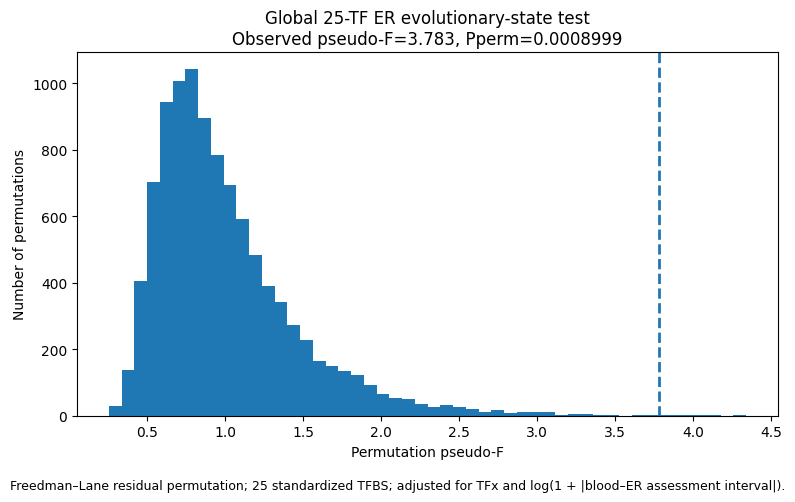


FINAL GLOBAL 25-TF SUMMARY
Patients: 239
TFBS: 25
Permutations: 10000
Global pseudo-F: 3.783274
Global partial R2: 0.031323
Global permutation p: 0.00089991

Pairwise global tests:
               Comparison  partial_R2  permutation_p    BH_q3
   ER loss vs ER retained    0.025144       0.001100 0.003300
Stable ER- vs ER retained    0.013348       0.014699 0.022048
    ER loss vs Stable ER-    0.042094       0.049595 0.049595

Dispersion diagnostic p: 0.331699

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/Global25TF_ER_Evolution


In [2]:
#!/usr/bin/env python3
# ======================================================================
# Q1) AURORA: GLOBAL 25-TF REGULATORY-PROGRAM TEST
#
# Primary question:
# Does the overall 25-TF Griffin mean-coverage profile differ across:
#   1. ER retained
#   2. ER loss
#   3. Stable ER-
# after adjustment for TFx and blood-to-ER timing?
#
# Method:
# Freedman-Lane residual permutation test
#
# Reduced model:
#   25-TF profile ~ TFx_pct + log(1 + abs_lag_days)
#
# Full model:
#   25-TF profile ~ Evolution_state + TFx_pct + log(1 + abs_lag_days)
#
# Primary statistic:
# Multivariate pseudo-F based on residual sum of squares across all
# 25 standardized TFBS.
#
# Primary outputs:
#   - global permutation p-value
#   - partial R2 for Evolution_state
#
# Secondary global pairwise tests:
#   - ER loss vs ER retained
#   - Stable ER- vs ER retained
#   - ER loss vs Stable ER-
# BH-FDR across the 3 pairwise GLOBAL tests.
#
# Seed = 1234
# Permutations = 10,000
# ======================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import levene
from statsmodels.stats.multitest import multipletests

SEED = 1234
N_PERM = 10000
rng = np.random.default_rng(SEED)

AURORA_BASE = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")
BASE_DIR = AURORA_BASE/"Griffin"/"Downstream"/"AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
INPUT_TSV = BASE_DIR/"Unified3Group_ER_Evolution_25TF"/"Unified3Group_239_analysis_dataset.tsv"
OUT_DIR = BASE_DIR/"Global25TF_ER_Evolution"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TF25 = [
    "ESR1","FOXA1","GATA3","PGR","GRHL2","STAT3","NFKB1","TFAP2C","XBP1",
    "FOXM1","FOXO3","AR","ESR2","FOXO1","RUNX1","E2F1","E2F7","TEAD1",
    "TEAD4","FOSL1","BACH1","HIF1A","ETS1","CEBPB","ELF3"
]
FEATURES = [f"{tf}_mean_coverage" for tf in TF25]
GROUP_ORDER = ["ER retained","ER loss","Stable ER-"]

# ======================================================================
# 1. LOAD 239-PATIENT UNIFIED DATASET
# ======================================================================

df = pd.read_csv(INPUT_TSV, sep="\t")
required = ["Evolution_state","TFx_pct","log_abs_lag"] + FEATURES
missing = [x for x in required if x not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df.loc[df["Evolution_state"].isin(GROUP_ORDER)].copy()
for col in ["TFx_pct","log_abs_lag"] + FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("="*80)
print("GLOBAL 25-TF ANALYSIS: INPUT QC")
print("="*80)
print(df["Evolution_state"].value_counts())
print("Total:", len(df))
print("Missing TFx:", df["TFx_pct"].isna().sum())
print("Missing timing:", df["log_abs_lag"].isna().sum())
print("Missing any 25-TF feature:", df[FEATURES].isna().any(axis=1).sum())

complete = df[required].notna().all(axis=1)
df = df.loc[complete].copy()

print("\nFinal complete-case cohort:")
print(df["Evolution_state"].value_counts())
print("Total:", len(df))

if len(df) != 239:
    print("WARNING: expected n=239 complete patients.")

# ======================================================================
# 2. STANDARDIZE ALL 25 TFBS
#
# Equalizes contribution of TFBS with different raw variances.
# Scaling is defined ONCE across the full 239-patient cohort.
# ======================================================================

Y_raw = df[FEATURES].to_numpy(dtype=float)
feature_means = Y_raw.mean(axis=0)
feature_sds = Y_raw.std(axis=0, ddof=1)

if np.any(feature_sds == 0):
    bad = np.array(TF25)[feature_sds == 0]
    raise ValueError(f"Zero-variance TFBS detected: {bad.tolist()}")

Yz = (Y_raw - feature_means) / feature_sds

scaling_df = pd.DataFrame({
    "TF": TF25,
    "mean_raw": feature_means,
    "sd_raw": feature_sds
})
scaling_df.to_csv(OUT_DIR/"Global25TF_scaling_parameters.tsv", sep="\t", index=False)

# ======================================================================
# 3. DESIGN MATRICES
#
# Reduced:
#   intercept + TFx + log_lag
#
# Full:
#   intercept + TFx + log_lag + ER_loss + Stable_ERneg
#
# ER retained = reference
# ======================================================================

df["ER_loss"] = (df["Evolution_state"] == "ER loss").astype(int)
df["Stable_ERneg"] = (df["Evolution_state"] == "Stable ER-").astype(int)

def build_design(data, include_group):
    base = np.column_stack([
        np.ones(len(data)),
        data["TFx_pct"].to_numpy(dtype=float),
        data["log_abs_lag"].to_numpy(dtype=float)
    ])
    if not include_group:
        return base
    return np.column_stack([
        base,
        (data["Evolution_state"] == "ER loss").astype(int).to_numpy(),
        (data["Evolution_state"] == "Stable ER-").astype(int).to_numpy()
    ])

# ======================================================================
# 4. MULTIVARIATE REGRESSION HELPERS
# ======================================================================

def orthonormal_basis(X):
    Q, _ = np.linalg.qr(X, mode="reduced")
    return Q

def fitted_and_residuals(Y, Q):
    fitted = Q @ (Q.T @ Y)
    residuals = Y - fitted
    return fitted, residuals

def residual_ss(Y, Q):
    fitted_component = Q.T @ Y
    return float(np.sum(Y**2) - np.sum(fitted_component**2))

def pseudo_f(Y, Q_reduced, Q_full, df_group, df_resid):
    sse_reduced = residual_ss(Y, Q_reduced)
    sse_full = residual_ss(Y, Q_full)
    ss_group = sse_reduced - sse_full
    F = (ss_group / df_group) / (sse_full / df_resid)
    partial_r2 = ss_group / sse_reduced
    return {
        "pseudo_F": float(F),
        "SSE_reduced": float(sse_reduced),
        "SSE_full": float(sse_full),
        "SS_state": float(ss_group),
        "partial_R2": float(partial_r2)
    }

# ======================================================================
# 5. FREEDMAN-LANE PERMUTATION TEST
# ======================================================================

def freedman_lane_test(data, Y, n_perm=10000, seed=1234):
    local_rng = np.random.default_rng(seed)
    X0 = build_design(data, include_group=False)
    X1 = build_design(data, include_group=True)
    Q0 = orthonormal_basis(X0)
    Q1 = orthonormal_basis(X1)
    df_group = X1.shape[1] - X0.shape[1]
    df_resid = len(data) - np.linalg.matrix_rank(X1)
    observed = pseudo_f(Y, Q0, Q1, df_group, df_resid)
    fitted0, resid0 = fitted_and_residuals(Y, Q0)
    perm_F = np.empty(n_perm, dtype=float)

    for b in range(n_perm):
        perm_idx = local_rng.permutation(len(data))
        Y_star = fitted0 + resid0[perm_idx, :]
        perm_F[b] = pseudo_f(
            Y_star, Q0, Q1, df_group, df_resid
        )["pseudo_F"]

    p_perm = (1 + np.sum(perm_F >= observed["pseudo_F"])) / (n_perm + 1)

    return {
        **observed,
        "df_group": df_group,
        "df_resid": df_resid,
        "n": len(data),
        "n_perm": n_perm,
        "permutation_p": float(p_perm),
        "perm_F": perm_F
    }

# ======================================================================
# 6. PRIMARY 3-GROUP GLOBAL TEST
# ======================================================================

overall = freedman_lane_test(
    data=df,
    Y=Yz,
    n_perm=N_PERM,
    seed=SEED
)

overall_summary = pd.DataFrame([{
    "Test": "ER retained vs ER loss vs Stable ER-",
    "n": overall["n"],
    "n_ER_retained": int((df["Evolution_state"]=="ER retained").sum()),
    "n_ER_loss": int((df["Evolution_state"]=="ER loss").sum()),
    "n_Stable_ERneg": int((df["Evolution_state"]=="Stable ER-").sum()),
    "pseudo_F": overall["pseudo_F"],
    "df_group": overall["df_group"],
    "df_resid": overall["df_resid"],
    "partial_R2": overall["partial_R2"],
    "permutation_p": overall["permutation_p"],
    "n_permutations": N_PERM
}])

print("\n"+"="*80)
print("PRIMARY GLOBAL 25-TF THREE-STATE TEST")
print("="*80)
print(overall_summary.to_string(index=False))

overall_summary.to_csv(
    OUT_DIR/"Global25TF_primary_three_state_test.tsv",
    sep="\t", index=False
)

pd.DataFrame({
    "permutation": np.arange(1, N_PERM+1),
    "null_pseudo_F": overall["perm_F"]
}).to_csv(
    OUT_DIR/"Global25TF_primary_null_distribution.tsv.gz",
    sep="\t", index=False, compression="gzip"
)

# ======================================================================
# 7. SECONDARY PAIRWISE GLOBAL PROGRAM TESTS
#
# Pairwise tests use the SAME full-cohort TFBS scaling.
# Each comparison has its own covariate-adjusted Freedman-Lane test.
# ======================================================================

PAIRWISE = [
    ("ER loss vs ER retained", "ER loss", "ER retained"),
    ("Stable ER- vs ER retained", "Stable ER-", "ER retained"),
    ("ER loss vs Stable ER-", "ER loss", "Stable ER-")
]

def build_pairwise_design(data, group1, group0, include_group):
    base = np.column_stack([
        np.ones(len(data)),
        data["TFx_pct"].to_numpy(dtype=float),
        data["log_abs_lag"].to_numpy(dtype=float)
    ])
    if not include_group:
        return base
    indicator = (data["Evolution_state"] == group1).astype(int).to_numpy()
    return np.column_stack([base, indicator])

def freedman_lane_pairwise(data, Y, group1, group0, n_perm=10000, seed=1234):
    X0 = build_pairwise_design(data, group1, group0, include_group=False)
    X1 = build_pairwise_design(data, group1, group0, include_group=True)
    Q0 = orthonormal_basis(X0)
    Q1 = orthonormal_basis(X1)
    df_group = 1
    df_resid = len(data) - np.linalg.matrix_rank(X1)
    observed = pseudo_f(Y, Q0, Q1, df_group, df_resid)
    fitted0, resid0 = fitted_and_residuals(Y, Q0)
    local_rng = np.random.default_rng(seed)
    perm_F = np.empty(n_perm, dtype=float)

    for b in range(n_perm):
        idx = local_rng.permutation(len(data))
        Y_star = fitted0 + resid0[idx, :]
        perm_F[b] = pseudo_f(
            Y_star, Q0, Q1, df_group, df_resid
        )["pseudo_F"]

    p_perm = (1 + np.sum(perm_F >= observed["pseudo_F"])) / (n_perm + 1)

    return {
        **observed,
        "n": len(data),
        "n_group1": int((data["Evolution_state"]==group1).sum()),
        "n_group0": int((data["Evolution_state"]==group0).sum()),
        "permutation_p": float(p_perm)
    }

pairwise_results = []

for i, (label, group1, group0) in enumerate(PAIRWISE):
    mask = df["Evolution_state"].isin([group1, group0]).to_numpy()
    dsub = df.loc[mask].copy()
    Ysub = Yz[mask, :]
    res = freedman_lane_pairwise(
        data=dsub,
        Y=Ysub,
        group1=group1,
        group0=group0,
        n_perm=N_PERM,
        seed=SEED+i+1
    )
    pairwise_results.append({
        "Comparison": label,
        "Group1": group1,
        "Group0": group0,
        "n": res["n"],
        "n_Group1": res["n_group1"],
        "n_Group0": res["n_group0"],
        "pseudo_F": res["pseudo_F"],
        "partial_R2": res["partial_R2"],
        "permutation_p": res["permutation_p"]
    })

pairwise_df = pd.DataFrame(pairwise_results)
pairwise_df["BH_q3"] = multipletests(
    pairwise_df["permutation_p"].to_numpy(),
    method="fdr_bh"
)[1]
pairwise_df["FDR_significant_q3"] = pairwise_df["BH_q3"] < 0.05

print("\n"+"="*80)
print("SECONDARY PAIRWISE GLOBAL 25-TF TESTS")
print("="*80)
print(pairwise_df.to_string(index=False))

pairwise_df.to_csv(
    OUT_DIR/"Global25TF_pairwise_program_tests.tsv",
    sep="\t", index=False
)

# ======================================================================
# 8. DISPERSION DIAGNOSTIC
#
# Important sensitivity:
# Tests whether one ER state simply has much greater multivariate spread.
#
# Residualize the 25-TF profile for TFx + timing, then calculate each
# patient's Euclidean distance from their ER-state centroid.
#
# Brown-Forsythe/Levene test is diagnostic, not primary inference.
# ======================================================================

X0 = build_design(df, include_group=False)
Q0 = orthonormal_basis(X0)
_, Y_resid = fitted_and_residuals(Yz, Q0)

distances = np.empty(len(df), dtype=float)

for group in GROUP_ORDER:
    idx = np.where(df["Evolution_state"].to_numpy() == group)[0]
    centroid = Y_resid[idx, :].mean(axis=0)
    distances[idx] = np.sqrt(
        np.sum((Y_resid[idx, :] - centroid)**2, axis=1)
    )

dispersion_patient_df = pd.DataFrame({
    "Evolution_state": df["Evolution_state"].to_numpy(),
    "distance_to_group_centroid": distances
})

dispersion_summary = (
    dispersion_patient_df
    .groupby("Evolution_state")["distance_to_group_centroid"]
    .agg(["count","mean","median","std"])
    .reset_index()
)

group_distance_arrays = [
    dispersion_patient_df.loc[
        dispersion_patient_df["Evolution_state"]==group,
        "distance_to_group_centroid"
    ].to_numpy()
    for group in GROUP_ORDER
]

lev_stat, lev_p = levene(
    *group_distance_arrays,
    center="median"
)

dispersion_test = pd.DataFrame([{
    "Test": "Brown-Forsythe multivariate dispersion diagnostic",
    "statistic": lev_stat,
    "p": lev_p
}])

print("\n"+"="*80)
print("MULTIVARIATE DISPERSION DIAGNOSTIC")
print("="*80)
print(dispersion_summary.to_string(index=False))
print("\nBrown-Forsythe p =", lev_p)

dispersion_patient_df.to_csv(
    OUT_DIR/"Global25TF_patient_dispersion.tsv",
    sep="\t", index=False
)
dispersion_summary.to_csv(
    OUT_DIR/"Global25TF_dispersion_summary.tsv",
    sep="\t", index=False
)
dispersion_test.to_csv(
    OUT_DIR/"Global25TF_dispersion_test.tsv",
    sep="\t", index=False
)

# ======================================================================
# 9. NULL-DISTRIBUTION FIGURE FOR PRIMARY GLOBAL TEST
# ======================================================================

fig, ax = plt.subplots(figsize=(8,5))
ax.hist(overall["perm_F"], bins=50)
ax.axvline(
    overall["pseudo_F"],
    linestyle="--",
    linewidth=2
)
ax.set_xlabel("Permutation pseudo-F")
ax.set_ylabel("Number of permutations")
ax.set_title(
    "Global 25-TF ER evolutionary-state test\n"
    f"Observed pseudo-F={overall['pseudo_F']:.3f}, "
    f"Pperm={overall['permutation_p']:.4g}"
)
fig.text(
    0.5, 0.01,
    "Freedman–Lane residual permutation; 25 standardized TFBS; "
    "adjusted for TFx and log(1 + |blood–ER assessment interval|).",
    ha="center", fontsize=9
)
plt.tight_layout(rect=[0,0.04,1,1])
fig.savefig(
    OUT_DIR/"Figure_Global25TF_primary_permutation_test.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    OUT_DIR/"Figure_Global25TF_primary_permutation_test.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ======================================================================
# 10. FINAL SUMMARY
# ======================================================================

print("\n"+"="*80)
print("FINAL GLOBAL 25-TF SUMMARY")
print("="*80)
print(f"Patients: {len(df)}")
print(f"TFBS: {len(TF25)}")
print(f"Permutations: {N_PERM}")
print(f"Global pseudo-F: {overall['pseudo_F']:.6f}")
print(f"Global partial R2: {overall['partial_R2']:.6f}")
print(f"Global permutation p: {overall['permutation_p']:.6g}")
print("\nPairwise global tests:")
print(
    pairwise_df[
        ["Comparison","partial_R2","permutation_p","BH_q3"]
    ].to_string(index=False)
)
print(f"\nDispersion diagnostic p: {lev_p:.6g}")
print("\nOutput directory:")
print(OUT_DIR)

FINAL COHORT
ER retained    179
Stable ER-      40
ER loss         20
Name: Evolution_state, dtype: int64
Total: 239

PAIRWISE GLOBAL 25-TF RESULTS
               Comparison     Group1      Group0   n  n_Group1  n_Group0  pseudo_F  partial_R2  permutation_p    BH_q3  FDR_significant_q3
   ER loss vs ER retained    ER loss ER retained 199        20       179  5.029609    0.025144       0.001100 0.003300                True
Stable ER- vs ER retained Stable ER- ER retained 219        40       179  2.908654    0.013348       0.014699 0.022048                True
    ER loss vs Stable ER-    ER loss  Stable ER-  60        20        40  2.460846    0.042094       0.049595 0.049595                True


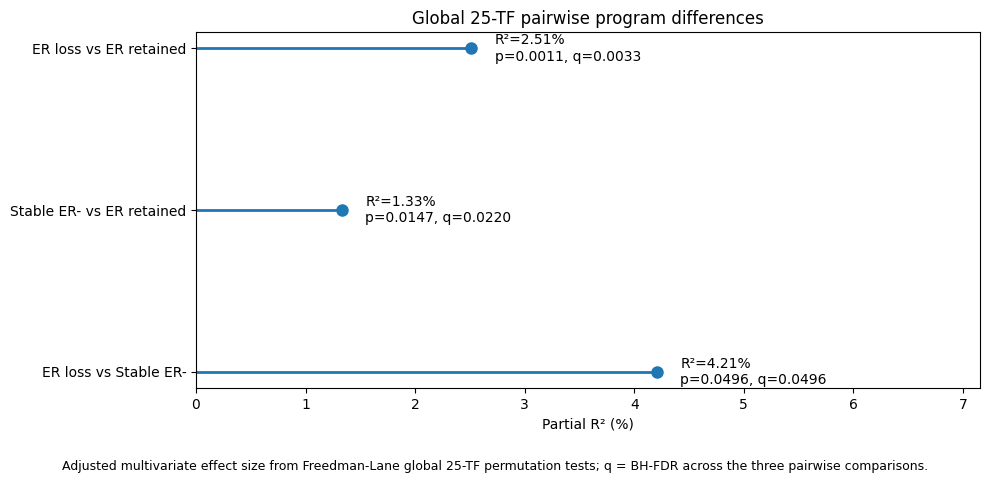

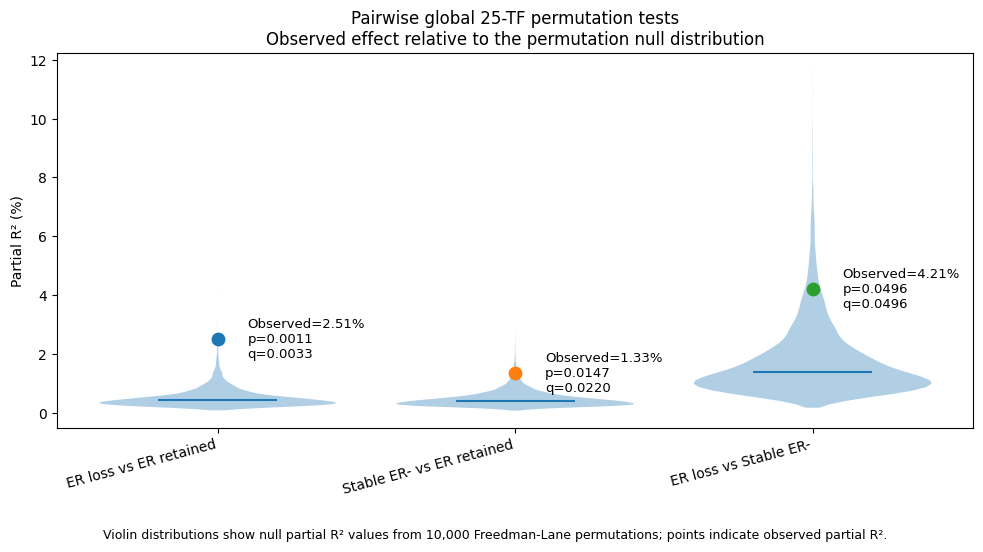


FINAL SUMMARY
Permutations: 10000

Pairwise results:
               Comparison  partial_R2  permutation_p    BH_q3
   ER loss vs ER retained    0.025144       0.001100 0.003300
Stable ER- vs ER retained    0.013348       0.014699 0.022048
    ER loss vs Stable ER-    0.042094       0.049595 0.049595

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/Global25TF_ER_Evolution/Pairwise_Global_Figures


In [3]:
#!/usr/bin/env python3
# ======================================================================
# Q1) AURORA: PAIRWISE GLOBAL 25-TF PERMUTATION FIGURES
#
# Outputs:
# 1. Pairwise global-test summary
# 2. Full permutation null distributions
# 3. Lollipop plot of observed partial R2
# 4. Violin plots of null partial R2 distributions
#
# Pairwise comparisons:
# - ER loss vs ER retained
# - Stable ER- vs ER retained
# - ER loss vs Stable ER-
#
# Model:
# Reduced: 25-TF profile ~ TFx + log_abs_lag
# Full:    25-TF profile ~ Group + TFx + log_abs_lag
#
# Freedman-Lane residual permutation
# Seed = 1234
# Permutations = 10,000
# ======================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

SEED=1234
N_PERM=10000

AURORA_BASE=Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")
BASE_DIR=AURORA_BASE/"Griffin"/"Downstream"/"AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
INPUT_TSV=BASE_DIR/"Unified3Group_ER_Evolution_25TF"/"Unified3Group_239_analysis_dataset.tsv"
OUT_DIR=BASE_DIR/"Global25TF_ER_Evolution"/"Pairwise_Global_Figures"
OUT_DIR.mkdir(parents=True,exist_ok=True)

TF25=[
    "ESR1","FOXA1","GATA3","PGR","GRHL2","STAT3","NFKB1","TFAP2C","XBP1",
    "FOXM1","FOXO3","AR","ESR2","FOXO1","RUNX1","E2F1","E2F7","TEAD1",
    "TEAD4","FOSL1","BACH1","HIF1A","ETS1","CEBPB","ELF3"
]
FEATURES=[f"{tf}_mean_coverage" for tf in TF25]

PAIRWISE=[
    ("ER loss vs ER retained","ER loss","ER retained"),
    ("Stable ER- vs ER retained","Stable ER-","ER retained"),
    ("ER loss vs Stable ER-","ER loss","Stable ER-")
]

# ======================================================================
# 1. LOAD DATA
# ======================================================================

df=pd.read_csv(INPUT_TSV,sep="\t")

required=["Evolution_state","TFx_pct","log_abs_lag"]+FEATURES
missing=[x for x in required if x not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df=df.loc[df["Evolution_state"].isin(
    ["ER retained","ER loss","Stable ER-"]
)].copy()

for col in ["TFx_pct","log_abs_lag"]+FEATURES:
    df[col]=pd.to_numeric(df[col],errors="coerce")

df=df.loc[df[required].notna().all(axis=1)].copy()

print("="*80)
print("FINAL COHORT")
print("="*80)
print(df["Evolution_state"].value_counts())
print("Total:",len(df))

# ======================================================================
# 2. STANDARDIZE TFBS USING FULL 239-PATIENT COHORT
# ======================================================================

Yraw=df[FEATURES].to_numpy(dtype=float)
means=Yraw.mean(axis=0)
sds=Yraw.std(axis=0,ddof=1)

if np.any(sds==0):
    raise ValueError("At least one TFBS has zero variance.")

Yz=(Yraw-means)/sds

# ======================================================================
# 3. HELPERS
# ======================================================================

def orthonormal_basis(X):
    Q,_=np.linalg.qr(X,mode="reduced")
    return Q

def fitted_and_residuals(Y,Q):
    fitted=Q@(Q.T@Y)
    resid=Y-fitted
    return fitted,resid

def residual_ss(Y,Q):
    return float(np.sum(Y**2)-np.sum((Q.T@Y)**2))

def pseudo_f_and_r2(Y,Q0,Q1,df_group,df_resid):
    sse0=residual_ss(Y,Q0)
    sse1=residual_ss(Y,Q1)
    ss_group=sse0-sse1
    F=(ss_group/df_group)/(sse1/df_resid)
    r2=ss_group/sse0
    return float(F),float(r2)

def build_pairwise_design(data,group1,include_group):
    base=np.column_stack([
        np.ones(len(data)),
        data["TFx_pct"].to_numpy(dtype=float),
        data["log_abs_lag"].to_numpy(dtype=float)
    ])
    if not include_group:
        return base
    indicator=(data["Evolution_state"]==group1).astype(int).to_numpy()
    return np.column_stack([base,indicator])

# ======================================================================
# 4. PAIRWISE FREEDMAN-LANE TEST
# ======================================================================

def run_pairwise_test(data,Y,group1,group0,n_perm,seed):
    X0=build_pairwise_design(data,group1,include_group=False)
    X1=build_pairwise_design(data,group1,include_group=True)

    Q0=orthonormal_basis(X0)
    Q1=orthonormal_basis(X1)

    df_group=1
    df_resid=len(data)-np.linalg.matrix_rank(X1)

    obs_F,obs_r2=pseudo_f_and_r2(
        Y,Q0,Q1,df_group,df_resid
    )

    fitted0,resid0=fitted_and_residuals(Y,Q0)
    rng=np.random.default_rng(seed)

    perm_F=np.empty(n_perm)
    perm_R2=np.empty(n_perm)

    for b in range(n_perm):
        idx=rng.permutation(len(data))
        Ystar=fitted0+resid0[idx,:]

        perm_F[b],perm_R2[b]=pseudo_f_and_r2(
            Ystar,Q0,Q1,df_group,df_resid
        )

    p_perm=(1+np.sum(perm_F>=obs_F))/(n_perm+1)

    return {
        "observed_F":obs_F,
        "observed_R2":obs_r2,
        "permutation_p":float(p_perm),
        "perm_F":perm_F,
        "perm_R2":perm_R2
    }

# ======================================================================
# 5. RUN ALL THREE PAIRWISE TESTS
# ======================================================================

summary_rows=[]
null_rows=[]

state_array=df["Evolution_state"].to_numpy()

for i,(label,group1,group0) in enumerate(PAIRWISE):
    mask=np.isin(state_array,[group1,group0])
    dsub=df.loc[mask].copy()
    Ysub=Yz[mask,:]

    result=run_pairwise_test(
        data=dsub,
        Y=Ysub,
        group1=group1,
        group0=group0,
        n_perm=N_PERM,
        seed=SEED+i+1
    )

    summary_rows.append({
        "Comparison":label,
        "Group1":group1,
        "Group0":group0,
        "n":len(dsub),
        "n_Group1":int((dsub["Evolution_state"]==group1).sum()),
        "n_Group0":int((dsub["Evolution_state"]==group0).sum()),
        "pseudo_F":result["observed_F"],
        "partial_R2":result["observed_R2"],
        "permutation_p":result["permutation_p"]
    })

    for b in range(N_PERM):
        null_rows.append({
            "Comparison":label,
            "permutation":b+1,
            "perm_pseudo_F":result["perm_F"][b],
            "perm_partial_R2":result["perm_R2"][b],
            "observed_pseudo_F":result["observed_F"],
            "observed_partial_R2":result["observed_R2"],
            "permutation_p":result["permutation_p"]
        })

summary_df=pd.DataFrame(summary_rows)
summary_df["BH_q3"]=multipletests(
    summary_df["permutation_p"].to_numpy(),
    method="fdr_bh"
)[1]
summary_df["FDR_significant_q3"]=summary_df["BH_q3"]<0.05

null_df=pd.DataFrame(null_rows)
null_df=null_df.merge(
    summary_df[["Comparison","BH_q3"]],
    on="Comparison",
    how="left"
)

print("\n"+"="*80)
print("PAIRWISE GLOBAL 25-TF RESULTS")
print("="*80)
print(summary_df.to_string(index=False))

summary_df.to_csv(
    OUT_DIR/"Global25TF_pairwise_program_tests.tsv",
    sep="\t",
    index=False
)

null_df.to_csv(
    OUT_DIR/"Global25TF_pairwise_permutation_null.tsv.gz",
    sep="\t",
    index=False,
    compression="gzip"
)

# ======================================================================
# 6. LOLLIPOP PLOT
# ======================================================================

plot_df=summary_df.copy()
plot_df["partial_R2_pct"]=100*plot_df["partial_R2"]

fig,ax=plt.subplots(figsize=(10,4.8))

y=np.arange(len(plot_df))[::-1]
values=plot_df["partial_R2_pct"].to_numpy()

for yi,val in zip(y,values):
    ax.hlines(yi,0,val,linewidth=2)

ax.plot(values,y,"o",markersize=8)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Comparison"])
ax.set_xlabel("Partial R² (%)")
ax.set_title("Global 25-TF pairwise program differences")

ax.set_xlim(0,max(values)*1.7)

for yi,(_,row) in zip(y,plot_df.iterrows()):
    ax.text(
        row["partial_R2_pct"]+max(values)*0.05,
        yi,
        f"R²={row['partial_R2_pct']:.2f}%\n"
        f"p={row['permutation_p']:.4f}, q={row['BH_q3']:.4f}",
        va="center",
        fontsize=10
    )

fig.text(
    0.5,0.01,
    "Adjusted multivariate effect size from Freedman-Lane global 25-TF permutation tests; "
    "q = BH-FDR across the three pairwise comparisons.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0,0.06,1,1])

fig.savefig(
    OUT_DIR/"Figure_Global25TF_pairwise_lollipop.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    OUT_DIR/"Figure_Global25TF_pairwise_lollipop.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ======================================================================
# 7. VIOLIN PLOT OF PERMUTATION NULL PARTIAL R2
#
# Violin = null distribution
# Dot = observed partial R2
# ======================================================================

order=[
    "ER loss vs ER retained",
    "Stable ER- vs ER retained",
    "ER loss vs Stable ER-"
]

datasets=[
    100*null_df.loc[
        null_df["Comparison"]==comparison,
        "perm_partial_R2"
    ].to_numpy()
    for comparison in order
]

fig,ax=plt.subplots(figsize=(10,5.5))

positions=np.arange(1,len(order)+1)

vp=ax.violinplot(
    datasets,
    positions=positions,
    widths=0.8,
    showmeans=False,
    showmedians=True,
    showextrema=False
)

for body in vp["bodies"]:
    body.set_alpha(0.35)

vp["cmedians"].set_linewidth(1.5)

for i,comparison in enumerate(order,1):
    row=summary_df.loc[
        summary_df["Comparison"]==comparison
    ].iloc[0]

    observed=100*row["partial_R2"]

    ax.scatter(
        i,
        observed,
        s=80,
        zorder=5
    )

    ax.text(
        i+0.10,
        observed,
        f"Observed={observed:.2f}%\n"
        f"p={row['permutation_p']:.4f}\n"
        f"q={row['BH_q3']:.4f}",
        va="center",
        fontsize=9.5
    )

ax.set_xticks(positions)
ax.set_xticklabels(
    order,
    rotation=15,
    ha="right"
)

ax.set_ylabel("Partial R² (%)")
ax.set_title(
    "Pairwise global 25-TF permutation tests\n"
    "Observed effect relative to the permutation null distribution"
)

fig.text(
    0.5,0.01,
    "Violin distributions show null partial R² values from 10,000 Freedman-Lane permutations; "
    "points indicate observed partial R².",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0,0.06,1,1])

fig.savefig(
    OUT_DIR/"Figure_Global25TF_pairwise_permutation_violin.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    OUT_DIR/"Figure_Global25TF_pairwise_permutation_violin.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ======================================================================
# 8. FINAL SUMMARY
# ======================================================================

print("\n"+"="*80)
print("FINAL SUMMARY")
print("="*80)
print(f"Permutations: {N_PERM}")
print("\nPairwise results:")
print(
    summary_df[
        ["Comparison","partial_R2","permutation_p","BH_q3"]
    ].to_string(index=False)
)
print("\nOutput directory:")
print(OUT_DIR)

INPUT COHORT
ER retained    179
Stable ER-      40
ER loss         20
Name: Evolution_state, dtype: int64
Total: 239
Fold 1: train=191, test=48
Fold 2: train=191, test=48
Fold 3: train=191, test=48
Fold 4: train=191, test=48
Fold 5: train=192, test=47

CROSS-FITTED ER REGULATORY-STATE SCORE
                 count      mean    median       std       min       max
Evolution_state                                                         
ER retained        179  0.042243  0.017615  1.196715 -5.553807  3.800152
ER loss             20  0.836934  0.524425  1.336925 -0.915878  4.364113
Stable ER-          40  0.738097  0.820714  0.858624 -1.200300  2.752135

OFF-AXIS DISTANCE
                 count      mean    median       std       min        max
Evolution_state                                                          
ER retained        179  4.311799  3.896072  1.550829  2.028270  11.888946
ER loss             20  5.332530  4.708413  2.763226  2.303830  14.469859
Stable ER-          40  4.73

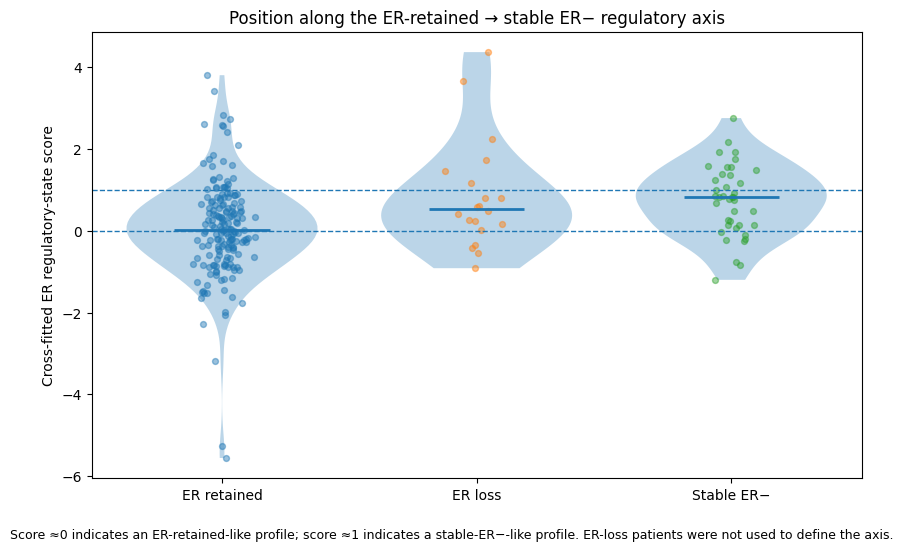

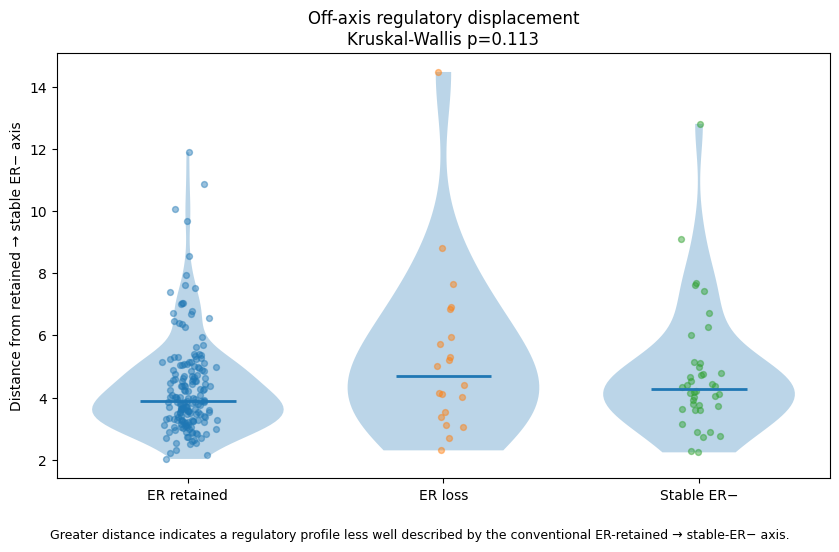

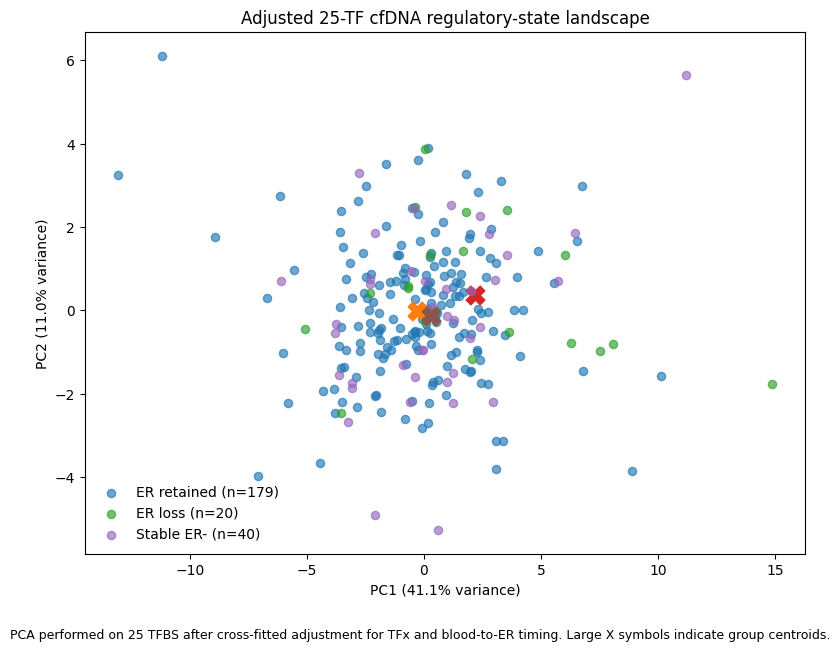


FINAL SUMMARY

State score medians:
                 count    median
Evolution_state                 
ER retained        179  0.017615
ER loss             20  0.524425
Stable ER-          40  0.820714

ER-loss state-score comparisons:
            Comparison  median_difference        p    BH_q2
ER loss vs ER retained           0.506810 0.016348 0.032696
 ER loss vs Stable ER-          -0.296288 0.610303 0.610303

Off-axis distance:
Global Kruskal-Wallis p = 0.112992
               Comparison  median_difference        p    BH_q3
   ER loss vs ER retained           0.812341 0.087416 0.241936
Stable ER- vs ER retained           0.366959 0.161291 0.241936
    ER loss vs Stable ER-           0.445382 0.495154 0.495154

PCA:
 PC  explained_variance_ratio  explained_variance_pct
PC1                  0.411334               41.133412
PC2                  0.110465               11.046496
PC3                  0.093822                9.382213

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDN

In [5]:
#!/usr/bin/env python3
# =====================================================================
# AURORA Q4: ER REGULATORY-STATE LANDSCAPE
#
# Question:
# Where does acquired ER loss reside in the multivariate 25-TF
# cfDNA regulatory-state landscape?
#
# Groups:
# ER retained  = Primary ER+ -> Met ER+   n=179
# ER loss      = Primary ER+ -> Met ER-   n=20
# Stable ER-   = Primary ER- -> Met ER-   n=40
#
# Step 1:
# Cross-fit nuisance adjustment:
# TFBS_j ~ TFx_pct + log_abs_lag
#
# Step 2:
# Define Retained -> Stable ER- regulatory axis using ONLY
# ER retained + Stable ER- patients.
#
# Step 3:
# Project ER-loss patients onto this axis.
#
# State score:
# 0 ~ ER-retained centroid
# 1 ~ Stable ER- centroid
#
# Off-axis distance:
# Distance from Retained -> Stable ER- regulatory axis.
#
# Reference-group patients are projected using leave-one-out centroids.
# ER-loss patients NEVER contribute to axis construction.
#
# Secondary:
# PCA of adjusted 25-TF profiles.
#
# Seed = 1234
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.decomposition import PCA

SEED=1234
N_BOOT=10000
rng=np.random.default_rng(SEED)

AURORA_BASE=Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")
BASE_DIR=AURORA_BASE/"Griffin"/"Downstream"/"AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
INPUT_TSV=BASE_DIR/"Unified3Group_ER_Evolution_25TF"/"Unified3Group_239_analysis_dataset.tsv"
OUT_DIR=BASE_DIR/"ER_Regulatory_State_Landscape_25TF"
OUT_DIR.mkdir(parents=True,exist_ok=True)

TF25=[
    "ESR1","FOXA1","GATA3","PGR","GRHL2","STAT3","NFKB1","TFAP2C","XBP1",
    "FOXM1","FOXO3","AR","ESR2","FOXO1","RUNX1","E2F1","E2F7","TEAD1",
    "TEAD4","FOSL1","BACH1","HIF1A","ETS1","CEBPB","ELF3"
]
FEATURES=[f"{tf}_mean_coverage" for tf in TF25]
GROUP_ORDER=["ER retained","ER loss","Stable ER-"]

# =====================================================================
# 1. LOAD DATA
# =====================================================================

df=pd.read_csv(INPUT_TSV,sep="\t")
required=["patient_id_norm","Evolution_state","TFx_pct","log_abs_lag"]+FEATURES
missing=[x for x in required if x not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df=df.loc[df["Evolution_state"].isin(GROUP_ORDER)].copy()
for col in ["TFx_pct","log_abs_lag"]+FEATURES:
    df[col]=pd.to_numeric(df[col],errors="coerce")
df=df.loc[df[required].notna().all(axis=1)].copy().reset_index(drop=True)

print("="*80)
print("INPUT COHORT")
print("="*80)
print(df["Evolution_state"].value_counts())
print("Total:",len(df))

if len(df)!=239:
    print("WARNING: expected n=239.")

# =====================================================================
# 2. 5-FOLD CROSS-FITTED TFx + TIMING ADJUSTMENT
#
# For each held-out patient:
# TFBS_j ~ TFx + log_abs_lag
#
# Regression coefficients are estimated without that patient's TFBS.
# =====================================================================

Y=df[FEATURES].to_numpy(dtype=float)
C=np.column_stack([
    np.ones(len(df)),
    df["TFx_pct"].to_numpy(dtype=float),
    df["log_abs_lag"].to_numpy(dtype=float)
])

Y_resid=np.full_like(Y,np.nan,dtype=float)

skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
groups=df["Evolution_state"].to_numpy()

for fold,(train_idx,test_idx) in enumerate(skf.split(np.zeros(len(df)),groups),1):
    Xtrain=C[train_idx,:]
    Xtest=C[test_idx,:]
    Ytrain=Y[train_idx,:]
    beta=np.linalg.lstsq(Xtrain,Ytrain,rcond=None)[0]
    pred=Xtest@beta
    Y_resid[test_idx,:]=Y[test_idx,:]-pred
    print(f"Fold {fold}: train={len(train_idx)}, test={len(test_idx)}")

if np.isnan(Y_resid).any():
    raise ValueError("Cross-fitted residual matrix contains missing values.")

# =====================================================================
# 3. STANDARDIZE ADJUSTED TFBS
#
# Scaling parameters defined using ONLY ER retained + Stable ER-
# reference states. ER-loss patients do not influence scaling.
# =====================================================================

reference_mask=df["Evolution_state"].isin(["ER retained","Stable ER-"]).to_numpy()
ref_resid=Y_resid[reference_mask,:]

ref_mean=ref_resid.mean(axis=0)
ref_sd=ref_resid.std(axis=0,ddof=1)

if np.any(ref_sd==0):
    bad=np.array(TF25)[ref_sd==0]
    raise ValueError(f"Zero-variance adjusted TFBS: {bad.tolist()}")

Z=(Y_resid-ref_mean)/ref_sd

scaling_df=pd.DataFrame({
    "TF":TF25,
    "reference_residual_mean":ref_mean,
    "reference_residual_sd":ref_sd
})
scaling_df.to_csv(
    OUT_DIR/"StateLandscape_25TF_scaling_parameters.tsv",
    sep="\t",index=False
)

# =====================================================================
# 4. AXIS FUNCTIONS
# =====================================================================

def make_axis(Ztrain,state_train):
    retained=Ztrain[state_train=="ER retained",:]
    stable=Ztrain[state_train=="Stable ER-",:]
    cR=retained.mean(axis=0)
    cS=stable.mean(axis=0)
    direction=cS-cR
    denom=np.dot(direction,direction)
    if denom<=0:
        raise ValueError("Retained and Stable ER- centroids are identical.")
    return cR,cS,direction,denom

def project_patient(x,cR,direction,denom):
    score=np.dot(x-cR,direction)/denom
    projected=cR+score*direction
    off_axis=np.linalg.norm(x-projected)
    return float(score),float(off_axis)

# =====================================================================
# 5. FULL REFERENCE AXIS
#
# Used for projecting all ER-loss patients.
# Loss patients do NOT contribute to construction.
# =====================================================================

ref_idx=np.where(reference_mask)[0]
Zref=Z[ref_idx,:]
state_ref=groups[ref_idx]

cR_full,cS_full,D_full,denom_full=make_axis(Zref,state_ref)

# =====================================================================
# 6. CROSS-FITTED / LEAVE-ONE-OUT STATE SCORES
#
# ER retained and Stable ER-:
# leave the patient out before calculating reference centroids.
#
# ER loss:
# project onto full axis defined from all Retained + Stable ER-.
# =====================================================================

state_score=np.empty(len(df))
off_axis=np.empty(len(df))

for i in range(len(df)):
    state=groups[i]
    if state=="ER loss":
        score,dist=project_patient(Z[i,:],cR_full,D_full,denom_full)
    else:
        train_ref_idx=ref_idx[ref_idx!=i]
        Ztrain=Z[train_ref_idx,:]
        strain=groups[train_ref_idx]
        cR,cS,D,denom=make_axis(Ztrain,strain)
        score,dist=project_patient(Z[i,:],cR,D,denom)
    state_score[i]=score
    off_axis[i]=dist

df["ER_state_score"]=state_score
df["off_axis_distance"]=off_axis

# =====================================================================
# 7. DESCRIPTIVE FULL-AXIS SCORE
#
# Useful for intuitive plotting:
# retained centroid = 0
# stable ER- centroid = 1
#
# Cross-fitted score remains preferred for inference.
# =====================================================================

full_score=np.empty(len(df))
full_distance=np.empty(len(df))

for i in range(len(df)):
    full_score[i],full_distance[i]=project_patient(
        Z[i,:],cR_full,D_full,denom_full
    )

df["ER_state_score_full_axis"]=full_score
df["off_axis_distance_full_axis"]=full_distance

# =====================================================================
# 8. GROUP SUMMARIES
# =====================================================================

score_summary=(
    df.groupby("Evolution_state")["ER_state_score"]
      .agg(["count","mean","median","std","min","max"])
      .reindex(GROUP_ORDER)
)

distance_summary=(
    df.groupby("Evolution_state")["off_axis_distance"]
      .agg(["count","mean","median","std","min","max"])
      .reindex(GROUP_ORDER)
)

print("\n"+"="*80)
print("CROSS-FITTED ER REGULATORY-STATE SCORE")
print("="*80)
print(score_summary)

print("\n"+"="*80)
print("OFF-AXIS DISTANCE")
print("="*80)
print(distance_summary)

# =====================================================================
# 9. BOOTSTRAP 95% CI FOR GROUP MEDIAN STATE SCORE
# =====================================================================

def bootstrap_median_ci(x,n_boot=10000,seed=1234):
    local_rng=np.random.default_rng(seed)
    x=np.asarray(x,dtype=float)
    boots=np.empty(n_boot)
    for b in range(n_boot):
        boots[b]=np.median(local_rng.choice(x,size=len(x),replace=True))
    return np.median(x),np.quantile(boots,0.025),np.quantile(boots,0.975)

boot_rows=[]

for i,state in enumerate(GROUP_ORDER):
    x=df.loc[df["Evolution_state"]==state,"ER_state_score"].to_numpy()
    med,low,high=bootstrap_median_ci(x,N_BOOT,SEED+i)
    boot_rows.append({
        "Evolution_state":state,
        "median_state_score":med,
        "bootstrap_CI95_low":low,
        "bootstrap_CI95_high":high
    })

boot_df=pd.DataFrame(boot_rows)

print("\n"+"="*80)
print("BOOTSTRAP MEDIAN STATE SCORE")
print("="*80)
print(boot_df.to_string(index=False))

# =====================================================================
# 10. STATE-SCORE PAIRWISE TESTS
#
# Important:
# Retained and Stable ER- define the axis, so the biologically important
# tests concern where ER loss falls relative to the two reference states.
# =====================================================================

score_pairs=[
    ("ER loss vs ER retained","ER loss","ER retained"),
    ("ER loss vs Stable ER-","ER loss","Stable ER-")
]

score_test_rows=[]

for label,g1,g0 in score_pairs:
    x=df.loc[df["Evolution_state"]==g1,"ER_state_score"]
    y=df.loc[df["Evolution_state"]==g0,"ER_state_score"]
    stat,p=mannwhitneyu(x,y,alternative="two-sided")
    score_test_rows.append({
        "Comparison":label,
        "median_Group1":np.median(x),
        "median_Group0":np.median(y),
        "median_difference":np.median(x)-np.median(y),
        "MannWhitney_U":stat,
        "p":p
    })

score_tests=pd.DataFrame(score_test_rows)
score_tests["BH_q2"]=multipletests(score_tests["p"],method="fdr_bh")[1]

print("\n"+"="*80)
print("ER-LOSS STATE-SCORE COMPARISONS")
print("="*80)
print(score_tests.to_string(index=False))

# =====================================================================
# 11. OFF-AXIS DISTANCE TESTS
# =====================================================================

distance_arrays=[
    df.loc[df["Evolution_state"]==state,"off_axis_distance"].to_numpy()
    for state in GROUP_ORDER
]

kw_stat,kw_p=kruskal(*distance_arrays)

distance_pairs=[
    ("ER loss vs ER retained","ER loss","ER retained"),
    ("Stable ER- vs ER retained","Stable ER-","ER retained"),
    ("ER loss vs Stable ER-","ER loss","Stable ER-")
]

distance_test_rows=[]

for label,g1,g0 in distance_pairs:
    x=df.loc[df["Evolution_state"]==g1,"off_axis_distance"]
    y=df.loc[df["Evolution_state"]==g0,"off_axis_distance"]
    stat,p=mannwhitneyu(x,y,alternative="two-sided")
    distance_test_rows.append({
        "Comparison":label,
        "median_Group1":np.median(x),
        "median_Group0":np.median(y),
        "median_difference":np.median(x)-np.median(y),
        "MannWhitney_U":stat,
        "p":p
    })

distance_tests=pd.DataFrame(distance_test_rows)
distance_tests["BH_q3"]=multipletests(distance_tests["p"],method="fdr_bh")[1]

print("\n"+"="*80)
print("OFF-AXIS DISTANCE GLOBAL TEST")
print("="*80)
print(f"Kruskal-Wallis H={kw_stat:.6f}, p={kw_p:.6g}")

print("\nPairwise:")
print(distance_tests.to_string(index=False))

# =====================================================================
# 12. PCA ON ADJUSTED 25-TF PROFILES
#
# Descriptive visualization only.
# =====================================================================

pca=PCA(n_components=5,random_state=SEED)
pcs=pca.fit_transform(Z)

df["PC1"]=pcs[:,0]
df["PC2"]=pcs[:,1]
df["PC3"]=pcs[:,2]

pca_variance=pd.DataFrame({
    "PC":[f"PC{i+1}" for i in range(5)],
    "explained_variance_ratio":pca.explained_variance_ratio_,
    "explained_variance_pct":100*pca.explained_variance_ratio_
})

loadings=pd.DataFrame(
    pca.components_.T,
    index=TF25,
    columns=[f"PC{i+1}" for i in range(5)]
).reset_index().rename(columns={"index":"TF"})

print("\n"+"="*80)
print("PCA EXPLAINED VARIANCE")
print("="*80)
print(pca_variance.to_string(index=False))

# =====================================================================
# 13. SAVE RESULTS
# =====================================================================

keep_cols=[
    "patient_id_norm","Evolution_state","TFx_pct","log_abs_lag",
    "ER_state_score","ER_state_score_full_axis",
    "off_axis_distance","off_axis_distance_full_axis",
    "PC1","PC2","PC3"
]

df[keep_cols].to_csv(
    OUT_DIR/"patient_regulatory_state_scores.tsv",
    sep="\t",index=False
)

score_summary.to_csv(
    OUT_DIR/"state_score_group_summary.tsv",
    sep="\t"
)

boot_df.to_csv(
    OUT_DIR/"state_score_bootstrap_medians.tsv",
    sep="\t",index=False
)

score_tests.to_csv(
    OUT_DIR/"ERloss_state_score_pairwise_tests.tsv",
    sep="\t",index=False
)

distance_summary.to_csv(
    OUT_DIR/"off_axis_distance_group_summary.tsv",
    sep="\t"
)

pd.DataFrame([{
    "Kruskal_Wallis_H":kw_stat,
    "p":kw_p
}]).to_csv(
    OUT_DIR/"off_axis_distance_global_test.tsv",
    sep="\t",index=False
)

distance_tests.to_csv(
    OUT_DIR/"off_axis_distance_pairwise_tests.tsv",
    sep="\t",index=False
)

pca_variance.to_csv(
    OUT_DIR/"PCA_explained_variance.tsv",
    sep="\t",index=False
)

loadings.to_csv(
    OUT_DIR/"PCA_loadings.tsv",
    sep="\t",index=False
)

# =====================================================================
# 14. FIGURE 1: STATE SCORE
# =====================================================================

fig,ax=plt.subplots(figsize=(8.5,5.5))

data=[
    df.loc[df["Evolution_state"]==g,"ER_state_score"].to_numpy()
    for g in GROUP_ORDER
]

positions=np.arange(1,4)

vp=ax.violinplot(
    data,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=True,
    showextrema=False
)

for body in vp["bodies"]:
    body.set_alpha(0.30)

vp["cmedians"].set_linewidth(2)

for i,(g,x) in enumerate(zip(GROUP_ORDER,data),1):
    jitter=rng.normal(i,0.045,size=len(x))
    ax.scatter(jitter,x,s=18,alpha=0.45)

ax.axhline(0,linestyle="--",linewidth=1)
ax.axhline(1,linestyle="--",linewidth=1)

ax.set_xticks(positions)
ax.set_xticklabels(["ER retained","ER loss","Stable ER−"])
ax.set_ylabel("Cross-fitted ER regulatory-state score")
ax.set_title("Position along the ER-retained → stable ER− regulatory axis")

fig.text(
    0.5,0.01,
    "Score ≈0 indicates an ER-retained-like profile; score ≈1 indicates a stable-ER−-like profile. "
    "ER-loss patients were not used to define the axis.",
    ha="center",fontsize=9
)

plt.tight_layout(rect=[0,0.05,1,1])

fig.savefig(
    OUT_DIR/"Figure_ER_regulatory_state_score.png",
    dpi=600,bbox_inches="tight"
)

fig.savefig(
    OUT_DIR/"Figure_ER_regulatory_state_score.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# =====================================================================
# 15. FIGURE 2: OFF-AXIS DISTANCE
# =====================================================================

fig,ax=plt.subplots(figsize=(8.5,5.5))

distance_data=[
    df.loc[df["Evolution_state"]==g,"off_axis_distance"].to_numpy()
    for g in GROUP_ORDER
]

vp=ax.violinplot(
    distance_data,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=True,
    showextrema=False
)

for body in vp["bodies"]:
    body.set_alpha(0.30)

vp["cmedians"].set_linewidth(2)

for i,x in enumerate(distance_data,1):
    jitter=rng.normal(i,0.045,size=len(x))
    ax.scatter(jitter,x,s=18,alpha=0.45)

ax.set_xticks(positions)
ax.set_xticklabels(["ER retained","ER loss","Stable ER−"])
ax.set_ylabel("Distance from retained → stable ER− axis")
ax.set_title(
    "Off-axis regulatory displacement\n"
    f"Kruskal-Wallis p={kw_p:.4g}"
)

fig.text(
    0.5,0.01,
    "Greater distance indicates a regulatory profile less well described by the conventional "
    "ER-retained → stable-ER− axis.",
    ha="center",fontsize=9
)

plt.tight_layout(rect=[0,0.05,1,1])

fig.savefig(
    OUT_DIR/"Figure_off_axis_distance.png",
    dpi=600,bbox_inches="tight"
)

fig.savefig(
    OUT_DIR/"Figure_off_axis_distance.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# =====================================================================
# 16. FIGURE 3: PCA REGULATORY LANDSCAPE
# =====================================================================

fig,ax=plt.subplots(figsize=(8,6.5))

for state in GROUP_ORDER:
    temp=df.loc[df["Evolution_state"]==state]
    ax.scatter(
        temp["PC1"],
        temp["PC2"],
        s=35,
        alpha=0.65,
        label=f"{state} (n={len(temp)})"
    )
    ax.scatter(
        temp["PC1"].mean(),
        temp["PC2"].mean(),
        s=180,
        marker="X"
    )

ax.set_xlabel(
    f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% variance)"
)

ax.set_title(
    "Adjusted 25-TF cfDNA regulatory-state landscape"
)

ax.legend(frameon=False)

fig.text(
    0.5,0.01,
    "PCA performed on 25 TFBS after cross-fitted adjustment for TFx and blood-to-ER timing. "
    "Large X symbols indicate group centroids.",
    ha="center",fontsize=9
)

plt.tight_layout(rect=[0,0.05,1,1])

fig.savefig(
    OUT_DIR/"Figure_adjusted_25TF_PCA.png",
    dpi=600,bbox_inches="tight"
)

fig.savefig(
    OUT_DIR/"Figure_adjusted_25TF_PCA.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# =====================================================================
# 17. FINAL SUMMARY
# =====================================================================

print("\n"+"="*80)
print("FINAL SUMMARY")
print("="*80)
print("\nState score medians:")
print(
    score_summary[["count","median"]].to_string()
)

print("\nER-loss state-score comparisons:")
print(
    score_tests[
        ["Comparison","median_difference","p","BH_q2"]
    ].to_string(index=False)
)

print("\nOff-axis distance:")
print(f"Global Kruskal-Wallis p = {kw_p:.6g}")
print(
    distance_tests[
        ["Comparison","median_difference","p","BH_q3"]
    ].to_string(index=False)
)

print("\nPCA:")
print(
    pca_variance.head(3).to_string(index=False)
)

print("\nOutput directory:")
print(OUT_DIR)